<a href="https://colab.research.google.com/github/musajalili/Advanced-Data-Analytics/blob/main/Pakistan_Mountain_Climate_Vulnerability_Mapping.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Remote Sensing and Machine Learning–Based Climate Vulnerability Mapping in the Mountain Regions of Pakistan

## 1. Operational methodology

| Vulnerability dimension | Indicator used in the primary CVI | Operational definition | Direction of vulnerability |
|---|---|---|---|
| **Exposure** | Land-surface temperature | Recent-minus-baseline June–August MODIS daytime LST anomaly | More positive warming = greater exposure |
|  | Precipitation anomaly | Absolute percent departure of recent mean annual CHIRPS precipitation from the baseline | Larger departure = greater exposure |
|  | Soil moisture | SMAP L4 root-zone soil-moisture deficit: baseline mean − recent mean | Larger deficit = greater exposure |
| **Sensitivity** | Vegetation condition | Recent-minus-baseline May–September MODIS NDVI anomaly | More negative change = greater sensitivity |
|  | Land-use characteristic | ESA WorldCover cropland fraction | Higher cropland share = greater sensitivity in this operational index |
|  | Population density | GHSL 2020 mountain-domain population / mountain area, log-transformed before normalization | Higher = greater sensitivity |
| **Adaptive-capacity deficit** | Accessibility to infrastructure | Travel time to nearest densely populated area | Longer = lower adaptive capacity |
|  | Accessibility to services | Travel time to nearest hospital/clinic | Longer = lower adaptive capacity |

### Temporal design

- **2016–2019:** baseline.
- **2020–2024:** recent assessment period.
- 2015 is deliberately excluded from the common dynamic baseline because SMAP L4 begins during 2015 rather than at the start of that calendar year.

### Mountain domain

Mountain terrain is delineated from SRTM using the core UNEP-WCMC/Kapos elevation–slope–local-relief criteria (classes 1–6):

- elevation ≥ 2500 m; or
- 1500–2500 m and slope ≥ 2°; or
- 1000–1500 m and slope ≥ 5° **or** 7-km local relief > 300 m; or
- 300–1000 m and 7-km local relief > 300 m.

The original cartographic “class 7” (small enclosed non-mountain areas) is not manufactured here. Grid cells enter the primary analysis when at least 50% of their clipped area is classified as mountain terrain. The notebook reports domain sensitivity at 25%, 50%, and 75% mountain-fraction thresholds.

### Index construction

Each primary indicator is robustly standardized to [0,1] using the 2nd and 98th percentiles and clipped outside that range. Indicators are equally weighted **within** each dimension, and the three dimensions are equally weighted in the primary CVI:

\[
CVI=\frac{Exposure+Sensitivity+AdaptiveCapacityDeficit}{3}.
\]

This equal-weight specification is explicit and testable. A Monte Carlo weight-sensitivity analysis evaluates whether the spatial ranking is robust when dimension weights vary over the full simplex.

### ML interpretation

Random Forest and XGBoost use the same substantive environmental/socioeconomic indicators that define the CVI. Spatial cross-validation uses broad geographic clusters to reduce optimistic performance estimates caused by spatial autocorrelation. High predictive performance therefore means the model successfully reproduces the index; it does **not** establish external validity or causality.

## Data sources and methodological references

Primary Earth Engine assets used in this implementation:

- **MODIS daytime land-surface temperature:** `MODIS/061/MOD11A2`
- **MODIS vegetation index:** `MODIS/061/MOD13A2`
- **CHIRPS daily precipitation:** `UCSB-CHG/CHIRPS/DAILY`
- **SMAP L4 root-zone soil moisture:** `NASA/SMAP/SPL4SMGP/008` (`sm_rootzone`, nominal Earth Engine pixel size 11 km)
- **ESA WorldCover 2021:** `ESA/WorldCover/v200`
- **GHSL population 2020:** `JRC/GHSL/P2023A/GHS_POP/2020`
- **Accessibility to cities 2015:** `projects/malariaatlasproject/assets/accessibility/accessibility_to_cities/2015_v1_0`
- **Accessibility to healthcare 2019:** `projects/malariaatlasproject/assets/accessibility/accessibility_to_healthcare/2019`
- **Terrain:** `USGS/SRTMGL1_003`
- **Default national boundary:** `FAO/GAUL/2015/level0`

Methodological references should be reported in the manuscript, including the UNEP-WCMC/Kapos mountain definition and the original source publications associated with each Earth Engine dataset. Dataset metadata, nominal spatial resolution, temporal coverage, QA flags, and licensing should be rechecked at the time of final publication because catalog metadata can be revised.

## 2. Installation and imports

In [ ]:
# Colab installation. Re-run after a fresh runtime restart.
!pip -q install --upgrade earthengine-api geopandas shapely pyarrow xgboost shap libpysal esda statsmodels

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 79.5/79.5 kB 2.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 482.5/482.5 kB 10.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.3/2.3 MB 43.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.1/50.1 MB 10.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.5/2.5 MB 32.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 247.8/247.8 kB 9.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 268.0/268.0 kB 9.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.8/10.8 MB 62.3 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires google-auth==2.49.0, but you have google-auth 2.61.0 which is incompatible.
google-colab 1.0.0 requires pandas==2.2.3, but you have pandas 3.0.6 which is incompatib

In [ ]:
!unzip -q /content/climate_vulnerability_abstract_aligned.zip -d /

In [ ]:
import os
import json
import math
import random
import warnings
from pathlib import Path

import ee
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import matplotlib as mpl
from shapely.geometry import mapping
from shapely import box as shapely_box, intersects as shapely_intersects, covered_by as shapely_covered_by
from shapely.validation import make_valid
from shapely.ops import unary_union

from sklearn.base import clone
from sklearn.model_selection import KFold, GroupKFold
from sklearn.cluster import KMeans
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from scipy.stats import spearmanr

import xgboost as xgb_module
from xgboost import XGBRegressor
import shap
from libpysal.weights import Queen, KNN
from esda.getisord import G_Local
from statsmodels.stats.multitest import multipletests

warnings.filterwarnings("ignore")

mpl.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 9,
    "axes.titlesize": 11,
    "axes.labelsize": 9,
    "xtick.labelsize": 8,
    "ytick.labelsize": 8,
    "legend.fontsize": 8,
    "figure.dpi": 120,
    "savefig.dpi": 600,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "axes.spines.top": False,
    "axes.spines.right": False,
})

print("Scientific Python stack imported.")

Scientific Python stack imported.


## 3. Reproducible configuration

In [ ]:
CONFIG = {
    "RANDOM_SEED": 42,

    # Preserve the starting notebook's configured Earth Engine project.
    # Change only if your authenticated EE project uses a different ID.
    "EE_PROJECT_ID": "ee-jalilimusa",

    "COUNTRY_NAMES": ["Pakistan"],
    "CUSTOM_AOI_ASSET": None,

    # Common dynamic record. 2015 is excluded because SMAP begins during 2015.
    "START_YEAR": 2016,
    "END_YEAR": 2024,
    "BASELINE_YEARS": (2016, 2019),
    "RECENT_YEARS": (2020, 2024),

    # Equal-area analysis grid matched to the nominal EE pixel size of SMAP L4.
    "GRID_CRS": "EPSG:6933",
    "MAP_CRS": "EPSG:6933",
    "GRID_RES_M": 11_000,

    # Mountain definition.
    "KAPOS_DEM_SCALE_M": 1_000,
    "KAPOS_RELIEF_RADIUS_M": 7_000,
    "MOUNTAIN_FRACTION_MIN": 0.50,
    "MOUNTAIN_THRESHOLD_AUDIT": [0.25, 0.50, 0.75],

    # Source-aware reduction scales.
    "EE_MODIS_SCALE_M": 1_000,
    "EE_CHIRPS_SCALE_M": 5_566,
    "EE_SMAP_SCALE_M": 11_000,
    "EE_ACCESS_SCALE_M": 927.67,
    "EE_TERRAIN_SCALE_M": 1_000,
    "EE_LANDCOVER_SCALE_M": 100,
    "EE_POP_SCALE_M": 100,
    "EE_MOUNTAIN_SCALE_M": 1_000,

    "POPULATION_YEAR": 2020,
    "N_VULNERABILITY_CLASSES": 5,

    # Robust, resumable extraction.
    "EXTRACTION_BATCH": 150,
    "MIN_RETRY_BATCH": 5,
    "TILESCALE": 8,
    "MAX_PIXELS_PER_REGION": 2_000_000,
    "EXTRACTION_VERSION": "abstract_aligned_v1",
    "SMAP_MONTHLY_BATCH": 250,
    "SMAP_TILESCALE": 16,

    # ML / spatial analysis.
    "N_SPATIAL_FOLDS": 5,
    "HOTSPOT_PERMUTATIONS": 499,
    "HOTSPOT_FDR_ALPHA": 0.05,
    "SENSITIVITY_RUNS": 1000,
    "MIN_LAYER_COVERAGE": 0.80,

    "SAVE_TO_DRIVE": False,
    "LOCAL_ROOT": "/content/climate_vulnerability_abstract_aligned",
}

random.seed(CONFIG["RANDOM_SEED"])
np.random.seed(CONFIG["RANDOM_SEED"])

ROOT = Path(CONFIG["LOCAL_ROOT"])
for sub in ["raw", "interim", "processed", "models", "figures", "exports", "logs"]:
    (ROOT / sub).mkdir(parents=True, exist_ok=True)

YEARS = list(range(CONFIG["START_YEAR"], CONFIG["END_YEAR"] + 1))
BASELINE_YEARS = list(range(CONFIG["BASELINE_YEARS"][0], CONFIG["BASELINE_YEARS"][1] + 1))
RECENT_YEARS = list(range(CONFIG["RECENT_YEARS"][0], CONFIG["RECENT_YEARS"][1] + 1))

with open(ROOT / "logs" / "configuration.json", "w") as f:
    json.dump(CONFIG, f, indent=2)

print(json.dumps(CONFIG, indent=2))

{
  "RANDOM_SEED": 42,
  "EE_PROJECT_ID": "ee-jalilimusa",
  "COUNTRY_NAMES": [
    "Pakistan"
  ],
  "CUSTOM_AOI_ASSET": null,
  "START_YEAR": 2016,
  "END_YEAR": 2024,
  "BASELINE_YEARS": [
    2016,
    2019
  ],
  "RECENT_YEARS": [
    2020,
    2024
  ],
  "GRID_CRS": "EPSG:6933",
  "MAP_CRS": "EPSG:6933",
  "GRID_RES_M": 11000,
  "KAPOS_DEM_SCALE_M": 1000,
  "KAPOS_RELIEF_RADIUS_M": 7000,
  "MOUNTAIN_FRACTION_MIN": 0.5,
  "MOUNTAIN_THRESHOLD_AUDIT": [
    0.25,
    0.5,
    0.75
  ],
  "EE_MODIS_SCALE_M": 1000,
  "EE_CHIRPS_SCALE_M": 5566,
  "EE_SMAP_SCALE_M": 11000,
  "EE_ACCESS_SCALE_M": 927.67,
  "EE_TERRAIN_SCALE_M": 1000,
  "EE_LANDCOVER_SCALE_M": 100,
  "EE_POP_SCALE_M": 100,
  "EE_MOUNTAIN_SCALE_M": 1000,
  "POPULATION_YEAR": 2020,
  "N_VULNERABILITY_CLASSES": 5,
  "EXTRACTION_BATCH": 150,
  "MIN_RETRY_BATCH": 5,
  "TILESCALE": 8,
  "MAX_PIXELS_PER_REGION": 2000000,
  "EXTRACTION_VERSION": "abstract_aligned_v1",
  "SMAP_MONTHLY_BATCH": 250,
  "SMAP_TILESCALE": 16,
  "N_SPA

## 4. Earth Engine authentication and national study boundary

In [ ]:
try:
    ee.Initialize(project=CONFIG["EE_PROJECT_ID"])
    print("Earth Engine initialized with configured project.")
except Exception:
    print("Earth Engine initialization failed; starting authentication flow.")
    ee.Authenticate()
    ee.Initialize(project=CONFIG["EE_PROJECT_ID"])
    print("Earth Engine initialized after authentication.")

if CONFIG["CUSTOM_AOI_ASSET"]:
    study_countries = ee.FeatureCollection(CONFIG["CUSTOM_AOI_ASSET"])
    boundary_source = CONFIG["CUSTOM_AOI_ASSET"]
else:
    gaul0 = ee.FeatureCollection("FAO/GAUL/2015/level0")
    study_countries = gaul0.filter(
        ee.Filter.inList("ADM0_NAME", CONFIG["COUNTRY_NAMES"])
    )
    boundary_source = "FAO/GAUL/2015/level0"

if study_countries.size().getInfo() == 0:
    raise RuntimeError("Study boundary query returned zero features.")

study_geom = study_countries.geometry()

boundary_geojson = study_countries.getInfo()
with open(ROOT / "raw" / "study_area.geojson", "w", encoding="utf-8") as f:
    json.dump(boundary_geojson, f)

boundary_gdf = gpd.GeoDataFrame.from_features(
    boundary_geojson["features"], crs="EPSG:4326"
).to_crs(CONFIG["GRID_CRS"])

study_union = boundary_gdf.geometry.union_all()
study_area_km2 = study_union.area / 1e6

print("Study boundary source:", boundary_source)
print("Study area:", CONFIG["COUNTRY_NAMES"])
print("Boundary area (km²):", round(study_area_km2, 2))
print(
    "IMPORTANT: administrative boundary products encode territorial conventions. "
    "Use CUSTOM_AOI_ASSET if your study requires a different declared convention."
)

Earth Engine initialization failed; starting authentication flow.


*** Earth Engine *** Share your feedback by taking our Annual Developer Satisfaction Survey: https://google.qualtrics.com/jfe/form/SV_9oS0DRcPvElRMNw?source=python


Earth Engine initialized after authentication.
Study boundary source: FAO/GAUL/2015/level0
Study area: ['Pakistan']
Boundary area (km²): 788428.04
IMPORTANT: administrative boundary products encode territorial conventions. Use CUSTOM_AOI_ASSET if your study requires a different declared convention.


## 5. Construct the national 11-km candidate grid

In [ ]:
minx, miny, maxx, maxy = study_union.bounds
res = int(CONFIG["GRID_RES_M"])

x0 = math.floor(minx / res) * res
y0 = math.floor(miny / res) * res
x1 = math.ceil(maxx / res) * res
y1 = math.ceil(maxy / res) * res

xs = np.arange(x0, x1, res, dtype=np.int64)
ys = np.arange(y0, y1, res, dtype=np.int64)
xx, yy = np.meshgrid(xs, ys, indexing="ij")
xx = xx.ravel()
yy = yy.ravel()

candidate_cells = shapely_box(xx, yy, xx + res, yy + res)
intersects_mask = shapely_intersects(candidate_cells, study_union)

valid_cells = candidate_cells[intersects_mask]
interior_mask = shapely_covered_by(valid_cells, study_union)

geoms = np.empty(len(valid_cells), dtype=object)
geoms[interior_mask] = valid_cells[interior_mask]

boundary_idx = np.flatnonzero(~interior_mask)
for i in boundary_idx:
    clipped = valid_cells[i].intersection(study_union)
    geoms[i] = clipped if (not clipped.is_empty and clipped.area > 0) else None

keep = np.array(
    [g is not None and not g.is_empty for g in geoms], dtype=bool
)
geoms = geoms[keep]

grid_country = gpd.GeoDataFrame(
    {"cell_id": np.arange(len(geoms), dtype=np.int64), "geometry": geoms},
    crs=CONFIG["GRID_CRS"],
)

grid_country["cell_area_km2"] = grid_country.geometry.area / 1e6
cent = grid_country.geometry.centroid
grid_country["centroid_x_m"] = cent.x.to_numpy()
grid_country["centroid_y_m"] = cent.y.to_numpy()

if not grid_country.geometry.is_valid.all():
    raise RuntimeError("Invalid grid geometry detected.")

grid_area_km2 = grid_country["cell_area_km2"].sum()
area_error_km2 = abs(grid_area_km2 - study_area_km2)
if area_error_km2 > 0.05:
    raise RuntimeError(
        f"Grid does not partition the study boundary: error={area_error_km2:.6f} km²"
    )

grid_country_ll = grid_country.to_crs("EPSG:4326")
grid_country_extract = grid_country_ll[["cell_id", "geometry"]].copy()

print(f"National candidate grid: {len(grid_country):,} cells")
print(f"Grid area error: {area_error_km2:.6f} km²")

National candidate grid: 6,931 cells
Grid area error: 0.000000 km²


## 6. Mountain mask and dynamic Earth-observation indicators

The core Kapos/UNEP-WCMC mountain criteria are reconstructed on a 1-km SRTM working surface. The SRTM image is clipped to a small buffer around the national boundary **before** the only forced 1-km reprojection, preventing the country-scale oversized reprojection failure encountered in earlier implementations.

In [ ]:
# ------------------------------------------------------------------
# Mountain definition
# ------------------------------------------------------------------
processing_geom = study_geom.buffer(CONFIG["KAPOS_RELIEF_RADIUS_M"] + 2_000)

dem_native = (
    ee.Image("USGS/SRTMGL1_003")
    .select("elevation")
    .clip(processing_geom)
)

# Aggregate before forcing the 1-km working projection.
dem_1km = (
    dem_native
    .reduceResolution(reducer=ee.Reducer.mean(), maxPixels=4096)
    .reproject(crs=dem_native.projection(), scale=CONFIG["KAPOS_DEM_SCALE_M"])
    .rename("elevation_m")
)

slope_1km = ee.Terrain.slope(dem_1km).rename("slope_deg")

relief_7km = (
    dem_1km.focalMax(
        radius=CONFIG["KAPOS_RELIEF_RADIUS_M"],
        units="meters",
        kernelType="circle",
    )
    .subtract(
        dem_1km.focalMin(
            radius=CONFIG["KAPOS_RELIEF_RADIUS_M"],
            units="meters",
            kernelType="circle",
        )
    )
    .rename("relief_7km_m")
)

e = dem_1km
s = slope_1km
r = relief_7km

class1 = e.gte(4500)
class2 = e.gte(3500).And(e.lt(4500))
class3 = e.gte(2500).And(e.lt(3500))
class4 = e.gte(1500).And(e.lt(2500)).And(s.gte(2))
class5 = (
    e.gte(1000).And(e.lt(1500))
    .And(s.gte(5).Or(r.gt(300)))
)
class6 = (
    e.gte(300).And(e.lt(1000))
    .And(r.gt(300))
)

mountain_core = (
    class1.Or(class2).Or(class3).Or(class4).Or(class5).Or(class6)
    .rename("mountain_core")
    .clip(study_geom)
)

kapos_class = (
    ee.Image(0)
    .where(class6, 6)
    .where(class5, 5)
    .where(class4, 4)
    .where(class3, 3)
    .where(class2, 2)
    .where(class1, 1)
    .rename("kapos_class")
    .clip(study_geom)
)

mountain_area_img = (
    ee.Image.pixelArea()
    .updateMask(mountain_core)
    .rename("mountain_area_m2")
)

# ------------------------------------------------------------------
# Dynamic datasets
# ------------------------------------------------------------------
MOD11 = ee.ImageCollection("MODIS/061/MOD11A2")
MOD13 = ee.ImageCollection("MODIS/061/MOD13A2")
CHIRPS = ee.ImageCollection("UCSB-CHG/CHIRPS/DAILY")
SMAP = ee.ImageCollection("NASA/SMAP/SPL4SMGP/008")

def period_filter(ic):
    return (
        ic.filterDate(
            f"{CONFIG['START_YEAR']}-01-01",
            f"{CONFIG['END_YEAR'] + 1}-01-01"
        )
        .filterBounds(study_geom)
    )

print("MOD11A2 images:", period_filter(MOD11).size().getInfo())
print("MOD13A2 images:", period_filter(MOD13).size().getInfo())
print("CHIRPS daily images:", period_filter(CHIRPS).size().getInfo())
print("SMAP L4 images:", period_filter(SMAP).size().getInfo())

def dates_for_year(year):
    return ee.Date.fromYMD(year, 1, 1), ee.Date.fromYMD(year + 1, 1, 1)

def mask_mod11_day(img):
    qa = img.select("QC_Day")
    mandatory = qa.bitwiseAnd(3).eq(0)
    data_quality = qa.rightShift(2).bitwiseAnd(3).eq(0)
    emissivity_error = qa.rightShift(4).bitwiseAnd(3).lte(1)
    lst_error = qa.rightShift(6).bitwiseAnd(3).lte(1)
    return img.updateMask(
        mandatory.And(data_quality).And(emissivity_error).And(lst_error)
    )

def mask_mod13(img):
    qa = img.select("DetailedQA")
    vi_quality = qa.bitwiseAnd(3).eq(0)
    usefulness = qa.rightShift(2).bitwiseAnd(15).lte(1)
    shadow = qa.rightShift(15).bitwiseAnd(1).eq(0)

    # Do not impose the MODIS snow bit as a hard exclusion here. In a mountain
    # study that would systematically erase persistent high-alpine terrain.
    # The primary vegetation signal is a recent-minus-baseline growing-season
    # NDVI anomaly; poor-quality/usefulness and shadow pixels remain excluded.
    return img.updateMask(
        vi_quality.And(usefulness).And(shadow)
    )

def annual_lst_summer(year):
    coll = (
        MOD11.filterDate(
            ee.Date.fromYMD(year, 6, 1),
            ee.Date.fromYMD(year, 9, 1),
        )
        .filterBounds(study_geom)
        .map(mask_mod11_day)
    )
    valid = coll.select("LST_Day_1km").count().gte(4)
    return (
        coll.select("LST_Day_1km").mean()
        .multiply(0.02).subtract(273.15)
        .updateMask(valid)
        .rename("lst_summer_c")
        .set("year", year)
    )

def annual_ndvi_growing(year):
    coll = (
        MOD13.filterDate(
            ee.Date.fromYMD(year, 5, 1),
            ee.Date.fromYMD(year, 10, 1),
        )
        .filterBounds(study_geom)
        .map(mask_mod13)
    )
    valid = coll.select("NDVI").count().gte(5)
    return (
        coll.select("NDVI").mean()
        .multiply(0.0001)
        .updateMask(valid)
        .rename("ndvi_growing")
        .set("year", year)
    )

def annual_chirps(year):
    start, end = dates_for_year(year)
    return (
        CHIRPS.filterDate(start, end)
        .filterBounds(study_geom)
        .select("precipitation")
        .sum()
        .rename("precip_mm")
        .set("year", year)
    )


# SMAP L4 is a 3-hourly collection. Do NOT build a 4- or 5-year mean image here:
# evaluating that graph inside reduceRegions can exceed the Earth Engine per-request
# user-memory limit even for a handful of polygons.
#
# SMAP is instead reduced month-by-month in Section 8. The monthly cell statistics
# are then combined in Python into baseline, recent, anomaly, and deficit metrics.
SMAP_NATIVE_PROJ = SMAP.select("sm_rootzone").first().projection()

def smap_monthly_mean_image(year, month):
    start = ee.Date.fromYMD(int(year), int(month), 1)
    end = start.advance(1, "month")
    coll = (
        SMAP.filterDate(start, end)
        .filterBounds(study_geom)
        .select("sm_rootzone")
    )
    mean_img = coll.mean()
    mean_img = mean_img.updateMask(
        mean_img.gte(0).And(mean_img.lte(0.9))
    )
    return mean_img.rename("sm_rootzone_monthly")

lst_yearly = ee.ImageCollection.fromImages(
    [annual_lst_summer(y) for y in YEARS]
)
ndvi_yearly = ee.ImageCollection.fromImages(
    [annual_ndvi_growing(y) for y in YEARS]
)
precip_yearly = ee.ImageCollection.fromImages(
    [annual_chirps(y) for y in YEARS]
)

def mean_over_years(ic, years, band):
    return (
        ic.filter(ee.Filter.inList("year", years))
        .select(band)
        .mean()
    )

lst_base = mean_over_years(lst_yearly, BASELINE_YEARS, "lst_summer_c")
lst_recent = mean_over_years(lst_yearly, RECENT_YEARS, "lst_summer_c").rename("lst_recent_c")
lst_anomaly = lst_recent.subtract(lst_base).rename("lst_anomaly_c")

ndvi_base = mean_over_years(ndvi_yearly, BASELINE_YEARS, "ndvi_growing")
ndvi_recent = mean_over_years(ndvi_yearly, RECENT_YEARS, "ndvi_growing").rename("ndvi_recent")
ndvi_anomaly = ndvi_recent.subtract(ndvi_base).rename("ndvi_anomaly")

precip_base = mean_over_years(precip_yearly, BASELINE_YEARS, "precip_mm")
precip_recent = mean_over_years(precip_yearly, RECENT_YEARS, "precip_mm").rename("precip_recent_mm")
precip_base_safe = precip_base.updateMask(precip_base.gt(1))
precip_anomaly_pct = (
    precip_recent.subtract(precip_base)
    .divide(precip_base_safe)
    .multiply(100)
    .rename("precip_anomaly_pct")
)
precip_anomaly_abs_pct = precip_anomaly_pct.abs().rename("precip_anomaly_abs_pct")

print("SMAP note: period statistics will be computed from monthly cell reductions in Section 8.")

print("Mountain definition and dynamic indicators prepared.")

MOD11A2 images: 414
MOD13A2 images: 207
CHIRPS daily images: 3288
SMAP L4 images: 26304
SMAP note: period statistics will be computed from monthly cell reductions in Section 8.
Mountain definition and dynamic indicators prepared.


## 7. Land use, population, accessibility, and contextual terrain

In [ ]:
access_city = (
    ee.Image(
        "projects/malariaatlasproject/assets/accessibility/"
        "accessibility_to_cities/2015_v1_0"
    )
    .select("accessibility")
    .rename("city_access_min")
    .updateMask(mountain_core)
)

access_health = (
    ee.Image(
        "projects/malariaatlasproject/assets/accessibility/"
        "accessibility_to_healthcare/2019"
    )
    .select("accessibility")
    .rename("health_access_min")
    .updateMask(mountain_core)
)

worldcover = (
    ee.ImageCollection("ESA/WorldCover/v200")
    .first()
    .select("Map")
)

# WorldCover is a 10-m categorical raster. Convert each target class to a
# binary image, aggregate exactly to an explicit 100-m target, and only then
# apply the ~1-km mountain mask. Explicitly fixing the target projection avoids
# an oversized reduceResolution kernel in a mixed-projection computation graph.
WORLD_COVER_NATIVE_PROJ = worldcover.projection()
LANDCOVER_TARGET_SCALE_M = int(CONFIG.get("EE_LANDCOVER_SCALE_M", 100))

worldcover_local = worldcover.clip(processing_geom)

def worldcover_fraction_100m(class_code, band_name):
    binary_10m = (
        worldcover_local.eq(int(class_code))
        .toFloat()
        .rename(band_name)
    )

    fraction_100m = (
        binary_10m
        .reduceResolution(
            reducer=ee.Reducer.mean(),
            maxPixels=256,
        )
        .reproject(
            crs=WORLD_COVER_NATIVE_PROJ,
            scale=LANDCOVER_TARGET_SCALE_M,
        )
    )

    return (
        fraction_100m
        .updateMask(mountain_core)
        .clip(study_geom)
        .rename(band_name)
    )

cropland_fraction_img = worldcover_fraction_100m(
    40, "cropland_fraction"
)

built_fraction_img = worldcover_fraction_100m(
    50, "built_fraction"
)

population_img = (
    ee.Image(f"JRC/GHSL/P2023A/GHS_POP/{CONFIG['POPULATION_YEAR']}")
    .select("population_count")
    .updateMask(mountain_core)
    .rename("population_sum")
)

terrain_image = ee.Image.cat([
    dem_1km.updateMask(mountain_core).rename("elevation_m"),
    slope_1km.updateMask(mountain_core).rename("slope_deg"),
    relief_7km.updateMask(mountain_core).rename("relief_7km_m"),
])

print("Static, population, terrain, and accessibility layers prepared.")

Static, population, terrain, and accessibility layers prepared.


## 8. Robust Earth Engine extraction and mountain-domain selection

The starting notebook's resumable batch extraction is retained. Each coherent source group is reduced at an appropriate scale; EPSG:6933 is the local analysis CRS but is **not** forced onto Earth Engine source rasters during `reduceRegions`.

The national grid is first reduced against the Kapos mountain-area mask. The primary analysis retains cells with mountain fraction ≥ 0.50. All retained cells keep their mountain fraction and estimated mountain area for transparent reporting.

In [ ]:
CONFIG.setdefault("SMAP_MONTHLY_BATCH", 800)
CONFIG.setdefault("SMAP_TILESCALE", 16)

print({
    "SMAP_MONTHLY_BATCH": CONFIG["SMAP_MONTHLY_BATCH"],
    "SMAP_TILESCALE": CONFIG["SMAP_TILESCALE"],
    "EE_SMAP_SCALE_M": CONFIG["EE_SMAP_SCALE_M"],
})

{'SMAP_MONTHLY_BATCH': 250, 'SMAP_TILESCALE': 16, 'EE_SMAP_SCALE_M': 11000}


In [ ]:
import re

def ee_feature_collection_from_gdf(gdf_batch):
    rows = []
    for row in gdf_batch.itertuples():
        geom = row.geometry

        if geom.is_empty:
            raise ValueError(f"Cell {row.cell_id} has an empty geometry.")
        if not geom.is_valid:
            geom = make_valid(geom)

        if geom.geom_type == "GeometryCollection":
            polygons = [
                g for g in geom.geoms
                if g.geom_type in ("Polygon", "MultiPolygon")
            ]
            if not polygons:
                raise ValueError(
                    f"Cell {row.cell_id} has no polygonal geometry."
                )
            geom = unary_union(polygons)

        if geom.geom_type not in ("Polygon", "MultiPolygon"):
            raise ValueError(
                f"Cell {row.cell_id} has unsupported geometry: {geom.geom_type}"
            )

        rows.append(
            ee.Feature(
                ee.Geometry(mapping(geom), geodesic=False),
                {"cell_id": int(row.cell_id)}
            )
        )

    return ee.FeatureCollection(rows)


def reduce_regions_checkpoint(image, grid_gdf, reducer, scale, tag):
    path = (
        ROOT / "interim" /
        f"{CONFIG['EXTRACTION_VERSION']}_{tag}_{CONFIG['GRID_RES_M']}m.csv"
    )

    completed = set()
    if path.exists():
        prev = pd.read_csv(path, usecols=["cell_id"])
        completed = set(prev["cell_id"].astype(int))
        print(f"{tag}: resuming with {len(completed):,} completed cells.")

    pending = grid_gdf[
        ~grid_gdf["cell_id"].isin(completed)
    ].copy()

    if pending.empty:
        return pd.read_csv(path)

    def process(batch_df):
        batch_fc = ee_feature_collection_from_gdf(batch_df)
        try:
            result = (
                image.reduceRegions(
                    collection=batch_fc,
                    reducer=reducer,
                    scale=float(scale),
                    crs=image.select([0]).projection(),
                    tileScale=CONFIG["TILESCALE"],
                    maxPixelsPerRegion=CONFIG["MAX_PIXELS_PER_REGION"],
                )
                .getInfo()
            )

            rows = [f["properties"] for f in result["features"]]
            returned_ids = {
                int(r["cell_id"])
                for r in rows
                if r.get("cell_id") is not None
            }
            requested_ids = set(batch_df["cell_id"].astype(int))

            if returned_ids != requested_ids:
                missing = sorted(requested_ids - returned_ids)
                raise RuntimeError(
                    f"Returned IDs do not match request; missing={missing[:10]}"
                )

            out_df = pd.DataFrame(rows)
            out_df.to_csv(
                path,
                mode="a",
                header=not path.exists(),
                index=False,
            )
            return len(out_df)

        except Exception as exc:
            if len(batch_df) > CONFIG["MIN_RETRY_BATCH"]:
                mid = max(1, len(batch_df) // 2)
                print(
                    f"{tag}: batch {len(batch_df)} failed; "
                    f"splitting {mid}+{len(batch_df)-mid}. Reason: {exc}"
                )
                return (
                    process(batch_df.iloc[:mid].copy())
                    + process(batch_df.iloc[mid:].copy())
                )
            raise RuntimeError(
                f"{tag}: minimum batch of {len(batch_df)} failed. Error: {exc}"
            ) from exc

    total = len(pending)
    for start_i in range(0, total, CONFIG["EXTRACTION_BATCH"]):
        batch = pending.iloc[
            start_i:start_i + CONFIG["EXTRACTION_BATCH"]
        ].copy()
        process(batch)
        print(
            f"{tag}: progress {min(start_i + len(batch), total):,}/{total:,}"
        )

    return pd.read_csv(path)


# ------------------------------------------------------------
# Step 1: mountain area for every national candidate cell.
# ------------------------------------------------------------
df_mountain = reduce_regions_checkpoint(
    mountain_area_img,
    grid_country_extract,
    ee.Reducer.sum(),
    CONFIG["EE_MOUNTAIN_SCALE_M"],
    "mountain_area",
)

if "mountain_area_m2" not in df_mountain.columns:
    if "sum" in df_mountain.columns:
        df_mountain = df_mountain.rename(columns={"sum": "mountain_area_m2"})
    else:
        raise RuntimeError(
            "Mountain-area extraction returned no recognized area field: "
            f"{df_mountain.columns.tolist()}"
        )

# RERUN-SAFE / IDEMPOTENT ATTACHMENT
# This cell may be re-executed after an Earth Engine interruption.  The previous
# execution may already have attached mountain-area derivatives to grid_country.
# Remove only those derived columns (including any legacy merge suffixes) before
# attaching the checkpointed result again.
_mountain_derived_prefixes = (
    "mountain_area_m2",
    "mountain_area_km2",
    "mountain_fraction",
)
_mountain_derived_cols = [
    c for c in grid_country.columns
    if any(
        c == prefix or c.startswith(prefix + "_")
        for prefix in _mountain_derived_prefixes
    )
]
if _mountain_derived_cols:
    print(
        "Rerun detected: replacing existing mountain-domain derivatives:",
        _mountain_derived_cols,
    )
    grid_country = grid_country.drop(columns=_mountain_derived_cols)

# Enforce one checkpoint row per national-grid cell before the join.
df_mountain_join = (
    df_mountain[["cell_id", "mountain_area_m2"]]
    .copy()
    .drop_duplicates(subset=["cell_id"], keep="last")
)
df_mountain_join["cell_id"] = df_mountain_join["cell_id"].astype(int)

if df_mountain_join["cell_id"].duplicated().any():
    raise RuntimeError("Duplicate cell_id values remain in the mountain-area checkpoint.")

grid_country = grid_country.merge(
    df_mountain_join,
    on="cell_id",
    how="left",
    validate="one_to_one",
)

grid_country["mountain_area_m2"] = (
    pd.to_numeric(grid_country["mountain_area_m2"], errors="coerce")
    .fillna(0.0)
)
grid_country["mountain_area_km2"] = grid_country["mountain_area_m2"] / 1e6
grid_country["mountain_fraction"] = (
    grid_country["mountain_area_m2"]
    / (grid_country["cell_area_km2"] * 1e6)
).clip(0, 1)

# Hard guards: rerunning must never leave merge-suffix artifacts or duplicate IDs.
_suffix_artifacts = [
    c for c in grid_country.columns
    if re.search(r"_(x|y)$", c)
]
if _suffix_artifacts:
    raise RuntimeError(
        "Unexpected merge-suffix columns remain after rerun-safe mountain join: "
        f"{_suffix_artifacts}"
    )
if grid_country["cell_id"].duplicated().any():
    raise RuntimeError("grid_country contains duplicate cell_id values after mountain join.")

domain_audit = []
for threshold in CONFIG["MOUNTAIN_THRESHOLD_AUDIT"]:
    tmp = grid_country[grid_country["mountain_fraction"] >= threshold]
    domain_audit.append({
        "mountain_fraction_threshold": threshold,
        "grid_cells": len(tmp),
        "estimated_mountain_area_km2": tmp["mountain_area_km2"].sum(),
    })

domain_audit = pd.DataFrame(domain_audit)
domain_audit.to_csv(
    ROOT / "exports" / "mountain_domain_threshold_audit.csv",
    index=False,
)
print(domain_audit)

grid = (
    grid_country[
        grid_country["mountain_fraction"] >= CONFIG["MOUNTAIN_FRACTION_MIN"]
    ]
    .copy()
    .reset_index(drop=True)
)

if len(grid) < 100:
    raise RuntimeError(
        "Mountain-domain selection returned implausibly few cells; inspect the mountain mask."
    )

grid_ll = grid.to_crs("EPSG:4326")
grid_extract = grid_ll[["cell_id", "geometry"]].copy()

centroids_projected = grid.geometry.centroid
centroids_ll = gpd.GeoSeries(
    centroids_projected, crs=grid.crs
).to_crs("EPSG:4326")
grid["centroid_lon"] = centroids_ll.x.to_numpy()
grid["centroid_lat"] = centroids_ll.y.to_numpy()

grid.to_file(
    ROOT / "interim" / "analysis_grid_mountains_11km.geojson",
    driver="GeoJSON",
)

print(
    f"Primary mountain domain: {len(grid):,} cells; "
    f"estimated mountain area={grid['mountain_area_km2'].sum():,.1f} km²"
)

# ------------------------------------------------------------
# Step 2: primary environmental and socioeconomic indicators.
# ------------------------------------------------------------
lst_image = ee.Image.cat([
    lst_recent,
    lst_anomaly,
]).updateMask(mountain_core)

ndvi_image = ee.Image.cat([
    ndvi_recent,
    ndvi_anomaly,
]).updateMask(mountain_core)

precip_image = ee.Image.cat([
    precip_recent,
    precip_anomaly_pct,
    precip_anomaly_abs_pct,
]).updateMask(mountain_core)


access_image = ee.Image.cat([access_city, access_health])
landcover_image = ee.Image.cat([cropland_fraction_img, built_fraction_img])
pop_image = population_img

print("Starting LST extraction...")
df_lst = reduce_regions_checkpoint(
    lst_image, grid_extract, ee.Reducer.mean(),
    CONFIG["EE_MODIS_SCALE_M"], "lst"
)

print("Starting NDVI extraction...")
df_ndvi = reduce_regions_checkpoint(
    ndvi_image, grid_extract, ee.Reducer.mean(),
    CONFIG["EE_MODIS_SCALE_M"], "ndvi"
)

print("Starting CHIRPS extraction...")
df_precip = reduce_regions_checkpoint(
    precip_image, grid_extract, ee.Reducer.mean(),
    CONFIG["EE_CHIRPS_SCALE_M"], "precip"
)

print("Starting memory-safe SMAP monthly extraction...")

# Backward compatibility for a live Colab runtime whose CONFIG dictionary was
# created by an earlier notebook version.  These setdefault calls preserve any
# user-specified values while supplying the memory-safe defaults when the new
# keys are absent.
CONFIG.setdefault("SMAP_MONTHLY_BATCH", 800)
CONFIG.setdefault("SMAP_TILESCALE", 16)

print(
    "SMAP execution settings:",
    {
        "monthly_batch": CONFIG["SMAP_MONTHLY_BATCH"],
        "tileScale": CONFIG["SMAP_TILESCALE"],
        "scale_m": CONFIG["EE_SMAP_SCALE_M"],
    },
)

def extract_smap_monthly_checkpoint(grid_gdf):
    """
    Reduce one monthly SMAP mean at a time to the analysis grid.

    Why this exists:
    NASA/SMAP/SPL4SMGP/008 is 3-hourly. A multi-year mean image can create a
    very large lazy computation graph and exceed Earth Engine's per-request
    user-memory limit. One-month composites contain only ~one month of source
    scenes, so each request remains bounded.

    The checkpoint is keyed by (year, month, cell_id), making the routine
    resumable after quota/network/runtime interruptions.
    """
    path = (
        ROOT / "interim" /
        f"{CONFIG['EXTRACTION_VERSION']}_smap_monthly_cell_stats_"
        f"{CONFIG['GRID_RES_M']}m.csv"
    )

    key_cols = ["year", "month", "cell_id"]
    value_col = "sm_rootzone_monthly"

    if path.exists():
        existing = pd.read_csv(path)
        missing_keys = [c for c in key_cols if c not in existing.columns]
        if missing_keys:
            raise RuntimeError(
                f"Existing SMAP checkpoint has incompatible schema; "
                f"missing {missing_keys}. Rename/delete {path} and rerun."
            )
        existing = existing.drop_duplicates(key_cols, keep="last")
        print(f"SMAP monthly checkpoint: {len(existing):,} completed cell-month rows.")
    else:
        existing = pd.DataFrame(columns=key_cols + [value_col, "n_source_images"])

    def append_rows(rows_df):
        rows_df.to_csv(
            path,
            mode="a",
            header=not path.exists(),
            index=False,
        )

    def reduce_month_batch(month_img, batch_df, year, month, n_source_images):
        batch_fc = ee_feature_collection_from_gdf(batch_df)

        try:
            result = (
                month_img.reduceRegions(
                    collection=batch_fc,
                    reducer=ee.Reducer.mean(),
                    scale=float(CONFIG["EE_SMAP_SCALE_M"]),
                    crs=SMAP_NATIVE_PROJ,
                    tileScale=int(CONFIG.get("SMAP_TILESCALE", 16)),
                    maxPixelsPerRegion=CONFIG["MAX_PIXELS_PER_REGION"],
                )
                .getInfo()
            )

            rows = [f["properties"] for f in result["features"]]
            out = pd.DataFrame(rows)

            if "cell_id" not in out.columns:
                raise RuntimeError("SMAP monthly reduction returned no cell_id.")

            if value_col not in out.columns:
                # For a one-band named image + mean reducer, Earth Engine should
                # normally preserve the band name. Handle the generic reducer
                # output defensively.
                if "mean" in out.columns:
                    out = out.rename(columns={"mean": value_col})
                else:
                    out[value_col] = np.nan

            requested_ids = set(batch_df["cell_id"].astype(int))
            returned_ids = set(out["cell_id"].dropna().astype(int))
            if returned_ids != requested_ids:
                missing = sorted(requested_ids - returned_ids)
                raise RuntimeError(
                    f"SMAP month {year}-{month:02d}: returned IDs do not match "
                    f"request; missing={missing[:10]}"
                )

            out["year"] = int(year)
            out["month"] = int(month)
            out["n_source_images"] = int(n_source_images)
            out = out[
                ["year", "month", "cell_id", value_col, "n_source_images"]
            ].copy()
            append_rows(out)
            return len(out)

        except Exception as exc:
            # The temporal graph is already bounded to one month. Recursive
            # spatial splitting is only a fallback for geometry/request size.
            if len(batch_df) > CONFIG["MIN_RETRY_BATCH"]:
                mid = max(1, len(batch_df) // 2)
                print(
                    f"SMAP {year}-{month:02d}: batch {len(batch_df)} failed; "
                    f"splitting {mid}+{len(batch_df)-mid}. Reason: {exc}"
                )
                return (
                    reduce_month_batch(
                        month_img,
                        batch_df.iloc[:mid].copy(),
                        year,
                        month,
                        n_source_images,
                    )
                    + reduce_month_batch(
                        month_img,
                        batch_df.iloc[mid:].copy(),
                        year,
                        month,
                        n_source_images,
                    )
                )
            raise RuntimeError(
                f"SMAP {year}-{month:02d}: minimum spatial batch "
                f"of {len(batch_df)} failed. Error: {exc}"
            ) from exc

    for year in YEARS:
        for month in range(1, 13):
            if path.exists():
                current = pd.read_csv(
                    path,
                    usecols=["year", "month", "cell_id"],
                )
                done_ids = set(
                    current.loc[
                        (current["year"] == year)
                        & (current["month"] == month),
                        "cell_id",
                    ].astype(int)
                )
            else:
                done_ids = set()

            pending = grid_gdf[
                ~grid_gdf["cell_id"].isin(done_ids)
            ].copy()

            if pending.empty:
                print(f"SMAP {year}-{month:02d}: complete ({len(done_ids):,} cells).")
                continue

            start = ee.Date.fromYMD(year, month, 1)
            end = start.advance(1, "month")
            month_coll = (
                SMAP.filterDate(start, end)
                .filterBounds(study_geom)
                .select("sm_rootzone")
            )
            n_source_images = int(month_coll.size().getInfo())
            if n_source_images == 0:
                raise RuntimeError(
                    f"SMAP returned zero source images for {year}-{month:02d}."
                )

            month_img = smap_monthly_mean_image(year, month)

            total = len(pending)
            batch_size = int(CONFIG.get("SMAP_MONTHLY_BATCH", 800))
            for start_i in range(0, total, batch_size):
                batch = pending.iloc[start_i:start_i + batch_size].copy()
                reduce_month_batch(
                    month_img,
                    batch,
                    year,
                    month,
                    n_source_images,
                )
                print(
                    f"SMAP {year}-{month:02d}: "
                    f"{min(start_i + len(batch), total):,}/{total:,} pending cells processed"
                )

    monthly = pd.read_csv(path)
    monthly = monthly.drop_duplicates(key_cols, keep="last")
    monthly["cell_id"] = monthly["cell_id"].astype(int)
    monthly["year"] = monthly["year"].astype(int)
    monthly["month"] = monthly["month"].astype(int)
    monthly["n_source_images"] = monthly["n_source_images"].astype(float)

    expected_rows = len(grid_gdf) * len(YEARS) * 12
    if len(monthly) != expected_rows:
        raise RuntimeError(
            f"SMAP monthly checkpoint has {len(monthly):,} unique rows; "
            f"expected {expected_rows:,}. Rerun this cell to resume."
        )

    return monthly


smap_monthly = extract_smap_monthly_checkpoint(grid_extract)

def weighted_period_mean(monthly_df, years, out_name):
    """Source-image-count-weighted monthly mean for every grid cell."""
    sub = monthly_df[monthly_df["year"].isin(years)].copy()
    sub = sub.dropna(subset=["sm_rootzone_monthly", "n_source_images"])

    if sub.empty:
        raise RuntimeError(f"No valid SMAP monthly values for {out_name}.")

    sub["_weighted"] = (
        sub["sm_rootzone_monthly"] * sub["n_source_images"]
    )

    agg = (
        sub.groupby("cell_id", as_index=False)
        .agg(
            weighted_sum=("_weighted", "sum"),
            weight_sum=("n_source_images", "sum"),
            valid_months=("sm_rootzone_monthly", "count"),
        )
    )
    agg[out_name] = agg["weighted_sum"] / agg["weight_sum"]
    return agg[["cell_id", out_name, "valid_months"]]


base_smap = weighted_period_mean(
    smap_monthly, BASELINE_YEARS, "sm_rootzone_baseline"
).rename(columns={"valid_months": "sm_baseline_valid_months"})

recent_smap = weighted_period_mean(
    smap_monthly, RECENT_YEARS, "sm_rootzone_recent"
).rename(columns={"valid_months": "sm_recent_valid_months"})

df_smap = (
    grid_extract[["cell_id"]]
    .merge(base_smap, on="cell_id", how="left", validate="one_to_one")
    .merge(recent_smap, on="cell_id", how="left", validate="one_to_one")
)

df_smap["sm_rootzone_anomaly"] = (
    df_smap["sm_rootzone_recent"]
    - df_smap["sm_rootzone_baseline"]
)
df_smap["sm_rootzone_deficit"] = (
    df_smap["sm_rootzone_baseline"]
    - df_smap["sm_rootzone_recent"]
)

# Persist a compact derived table used by the remainder of the notebook.
df_smap.to_csv(
    ROOT / "interim" /
    f"{CONFIG['EXTRACTION_VERSION']}_smap_period_stats_"
    f"{CONFIG['GRID_RES_M']}m.csv",
    index=False,
)

print("SMAP period statistics:")
print(
    df_smap[
        [
            "sm_rootzone_baseline",
            "sm_rootzone_recent",
            "sm_rootzone_anomaly",
            "sm_rootzone_deficit",
        ]
    ].describe()
)

print("Starting accessibility extraction...")
df_access = reduce_regions_checkpoint(
    access_image, grid_extract, ee.Reducer.mean(),
    CONFIG["EE_ACCESS_SCALE_M"], "access"
)

print("Starting land-cover extraction (explicit 10 m -> 100 m aggregation)...")
df_landcover = reduce_regions_checkpoint(
    landcover_image, grid_extract, ee.Reducer.mean(),
    CONFIG["EE_LANDCOVER_SCALE_M"], "landcover_v2"
)

print("Starting population extraction...")
df_pop = reduce_regions_checkpoint(
    pop_image, grid_extract, ee.Reducer.sum(),
    CONFIG["EE_POP_SCALE_M"], "population"
)

print("Starting terrain-context extraction...")
df_terrain = reduce_regions_checkpoint(
    terrain_image, grid_extract, ee.Reducer.mean(),
    CONFIG["EE_TERRAIN_SCALE_M"], "terrain"
)

if "population_sum" not in df_pop.columns:
    if "population_count" in df_pop.columns:
        df_pop = df_pop.rename(columns={"population_count": "population_sum"})
    elif "sum" in df_pop.columns:
        df_pop = df_pop.rename(columns={"sum": "population_sum"})
    else:
        raise RuntimeError(
            "Population extraction returned no recognized population field: "
            f"{df_pop.columns.tolist()}"
        )

print({
    "LST": df_lst.shape,
    "NDVI": df_ndvi.shape,
    "precip": df_precip.shape,
    "SMAP": df_smap.shape,
    "access": df_access.shape,
    "landcover": df_landcover.shape,
    "population": df_pop.shape,
    "terrain": df_terrain.shape,
})

mountain_area: resuming with 6,931 completed cells.
   mountain_fraction_threshold  grid_cells  estimated_mountain_area_km2
0                         0.25        2714                254609.160074
1                         0.50        2358                238766.154072
2                         0.75        1909                205690.901182
Primary mountain domain: 2,358 cells; estimated mountain area=238,766.2 km²
Starting LST extraction...
lst: resuming with 2,358 completed cells.
Starting NDVI extraction...
ndvi: resuming with 2,358 completed cells.
Starting CHIRPS extraction...
precip: resuming with 2,358 completed cells.
Starting memory-safe SMAP monthly extraction...
SMAP execution settings: {'monthly_batch': 250, 'tileScale': 16, 'scale_m': 11000}
SMAP monthly checkpoint: 254,664 completed cell-month rows.
SMAP 2016-01: complete (2,358 cells).
SMAP 2016-02: complete (2,358 cells).
SMAP 2016-03: complete (2,358 cells).
SMAP 2016-04: complete (2,358 cells).
SMAP 2016-05: complete (2,

In [ ]:
!zip -r climate_vulnerability_abstract_aligned.zip /content/climate_vulnerability_abstract_aligned

  adding: content/climate_vulnerability_abstract_aligned/ (stored 0%)
  adding: content/climate_vulnerability_abstract_aligned/raw/ (stored 0%)
  adding: content/climate_vulnerability_abstract_aligned/raw/study_area.geojson (deflated 63%)
  adding: content/climate_vulnerability_abstract_aligned/interim/ (stored 0%)
  adding: content/climate_vulnerability_abstract_aligned/interim/abstract_aligned_v1_landcover_v2_11000m.csv (deflated 55%)
  adding: content/climate_vulnerability_abstract_aligned/interim/abstract_aligned_v1_lst_11000m.csv (deflated 52%)
  adding: content/climate_vulnerability_abstract_aligned/interim/abstract_aligned_v1_access_11000m.csv (deflated 50%)
  adding: content/climate_vulnerability_abstract_aligned/interim/analysis_grid_mountains_11km.geojson (deflated 82%)
  adding: content/climate_vulnerability_abstract_aligned/interim/abstract_aligned_v1_terrain_11000m.csv (deflated 50%)
  adding: content/climate_vulnerability_abstract_aligned/interim/abstract_aligned_v1_ndvi_

## 9. Harmonization, spatial-support checks, and missing-data quality control

In [ ]:
base_cols = [
    "cell_id", "cell_area_km2", "mountain_area_km2", "mountain_fraction",
    "centroid_x_m", "centroid_y_m", "centroid_lon", "centroid_lat",
]

# Safely load the grid from disk if it's missing in kernel memory
if 'grid' not in globals():
    grid_path = ROOT / "interim" / "analysis_grid_mountains_11km.geojson"
    print(f"'grid' variable not found in memory; loading from {grid_path}")
    grid = gpd.read_file(grid_path)

df_all = (
    grid[base_cols]
    .merge(df_lst, on="cell_id", how="left", validate="one_to_one")
    .merge(df_ndvi, on="cell_id", how="left", validate="one_to_one")
    .merge(df_precip, on="cell_id", how="left", validate="one_to_one")
    .merge(df_smap, on="cell_id", how="left", validate="one_to_one")
    .merge(df_access, on="cell_id", how="left", validate="one_to_one")
    .merge(df_landcover, on="cell_id", how="left", validate="one_to_one")
    .merge(df_pop[["cell_id", "population_sum"]], on="cell_id", how="left", validate="one_to_one")
    .merge(df_terrain, on="cell_id", how="left", validate="one_to_one")
)

dup_cols = [c for c in df_all.columns if c.endswith("_x") or c.endswith("_y")]
if dup_cols:
    raise RuntimeError(f"Unexpected duplicated columns after joins: {dup_cols}")

if (df_all["mountain_area_km2"] <= 0).any():
    raise RuntimeError("Selected mountain-domain cells contain non-positive mountain area.")

df_all["population_density"] = (
    df_all["population_sum"] / df_all["mountain_area_km2"]
)
df_all["log_population_density"] = np.log1p(
    df_all["population_density"].clip(lower=0)
)

PRIMARY_INDICATORS = [
    "lst_anomaly_c",
    "precip_anomaly_abs_pct",
    "sm_rootzone_deficit",
    "ndvi_anomaly",
    "cropland_fraction",
    "population_density",
    "city_access_min",
    "health_access_min",
]

DIAGNOSTIC_INDICATORS = [
    "lst_anomaly_c",
    "precip_anomaly_pct",
    "sm_rootzone_anomaly",
    "ndvi_anomaly",
    "built_fraction",
    "elevation_m",
    "slope_deg",
    "relief_7km_m",
]

missing_primary = (
    df_all[PRIMARY_INDICATORS]
    .isna().mean()
    .sort_values(ascending=False)
    .rename("missing_fraction")
)
print("Primary-indicator missingness:")
print(missing_primary)

coverage = 1 - missing_primary
low_coverage = coverage[coverage < CONFIG["MIN_LAYER_COVERAGE"]]
if not low_coverage.empty:
    raise RuntimeError(
        "Primary indicator coverage is below the configured threshold:\n"
        f"{low_coverage}"
    )

primary_complete = df_all[PRIMARY_INDICATORS].notna().all(axis=1)
df = df_all.loc[primary_complete].copy()

print(
    f"Complete primary CVI cells: {len(df):,}/{len(df_all):,} "
    f"({len(df)/len(df_all):.1%})"
)

if len(df) / len(df_all) < 0.75:
    raise RuntimeError(
        "Less than 75% of the selected mountain grid is complete across all primary indicators."
    )

df_all.to_parquet(
    ROOT / "processed" / "mountain_grid_all.parquet",
    index=False,
)
df.to_parquet(
    ROOT / "processed" / "mountain_grid_primary_complete.parquet",
    index=False,
)

Primary-indicator missingness:
lst_anomaly_c             0.162426
precip_anomaly_abs_pct    0.045802
ndvi_anomaly              0.017388
sm_rootzone_deficit       0.003817
cropland_fraction         0.000000
population_density        0.000000
city_access_min           0.000000
health_access_min         0.000000
Name: missing_fraction, dtype: float64
Complete primary CVI cells: 1,842/2,358 (78.1%)


## 10. Standardization and construction of Exposure, Sensitivity, Adaptive-Capacity Deficit, and CVI

In [ ]:
def robust_minmax(series, q_low=0.02, q_high=0.98):
    """Robust percentile normalization to [0,1] with explicit clipping."""
    s = pd.to_numeric(series, errors="coerce").astype(float)
    lo = float(s.quantile(q_low))
    hi = float(s.quantile(q_high))
    if not np.isfinite(lo) or not np.isfinite(hi) or hi <= lo:
        raise ValueError(
            f"Degenerate normalization range: low={lo}, high={hi}"
        )
    return (s.clip(lo, hi) - lo) / (hi - lo), {
        "q_low": q_low,
        "q_high": q_high,
        "low": lo,
        "high": hi,
    }

normalization_stats = {}
df = df.copy()

# Exposure
df["exp_heat"], normalization_stats["lst_anomaly_c"] = robust_minmax(
    df["lst_anomaly_c"]
)
df["exp_precip_variability"], normalization_stats["precip_anomaly_abs_pct"] = robust_minmax(
    df["precip_anomaly_abs_pct"]
)
df["exp_soil_moisture_deficit"], normalization_stats["sm_rootzone_deficit"] = robust_minmax(
    df["sm_rootzone_deficit"]
)
df["Exposure"] = df[
    ["exp_heat", "exp_precip_variability", "exp_soil_moisture_deficit"]
].mean(axis=1)

# Sensitivity
ndvi_decline = -df["ndvi_anomaly"]
df["sens_vegetation_decline"], normalization_stats["negative_ndvi_anomaly"] = robust_minmax(
    ndvi_decline
)

df["sens_cropland"], normalization_stats["cropland_fraction"] = robust_minmax(
    df["cropland_fraction"]
)
df["sens_population"], normalization_stats["log_population_density"] = robust_minmax(
    df["log_population_density"]
)
df["Sensitivity"] = df[
    ["sens_vegetation_decline", "sens_cropland", "sens_population"]
].mean(axis=1)

# Adaptive-capacity deficit: longer travel time is worse.
df["acd_city"], normalization_stats["city_access_min"] = robust_minmax(
    df["city_access_min"]
)
df["acd_health"], normalization_stats["health_access_min"] = robust_minmax(
    df["health_access_min"]
)
df["AdaptiveCapacityDeficit"] = df[["acd_city", "acd_health"]].mean(axis=1)
df["AdaptiveCapacity"] = 1 - df["AdaptiveCapacityDeficit"]

# Equal dimension weights are the primary, explicit specification.
df["V_index"] = df[
    ["Exposure", "Sensitivity", "AdaptiveCapacityDeficit"]
].mean(axis=1)

if not df["V_index"].between(0, 1).all():
    raise RuntimeError("Vulnerability index escaped [0,1].")

rank_pct = df["V_index"].rank(method="average", pct=True)
df["V_class_id"] = pd.cut(
    rank_pct,
    bins=[0, .2, .4, .6, .8, 1.0],
    labels=False,
    include_lowest=True,
).astype("Int64")

class_map = {
    0: "Q1 Lowest",
    1: "Q2",
    2: "Q3",
    3: "Q4",
    4: "Q5 Highest",
}
df["V_class"] = df["V_class_id"].map(class_map)

with open(ROOT / "logs" / "normalization_stats.json", "w") as f:
    json.dump(normalization_stats, f, indent=2)

df.to_parquet(
    ROOT / "processed" / "vulnerability_grid.parquet",
    index=False,
)

print(df[
    ["Exposure", "Sensitivity", "AdaptiveCapacityDeficit", "V_index"]
].describe())
print(df["V_class"].value_counts(dropna=False).sort_index())

          Exposure  Sensitivity  AdaptiveCapacityDeficit      V_index
count  1842.000000  1842.000000              1842.000000  1842.000000
mean      0.406368     0.350200                 0.246241     0.334270
std       0.129999     0.163291                 0.214903     0.093745
min       0.056561     0.000000                 0.000000     0.137031
25%       0.314981     0.245244                 0.087572     0.270040
50%       0.412516     0.322126                 0.191306     0.324247
75%       0.497074     0.442646                 0.340072     0.385196
max       0.760302     0.985512                 1.000000     0.701810
V_class
Q1 Lowest     368
Q2            368
Q3            369
Q4            368
Q5 Highest    369
Name: count, dtype: int64


## 11. Indicator relationships and multicollinearity diagnostics

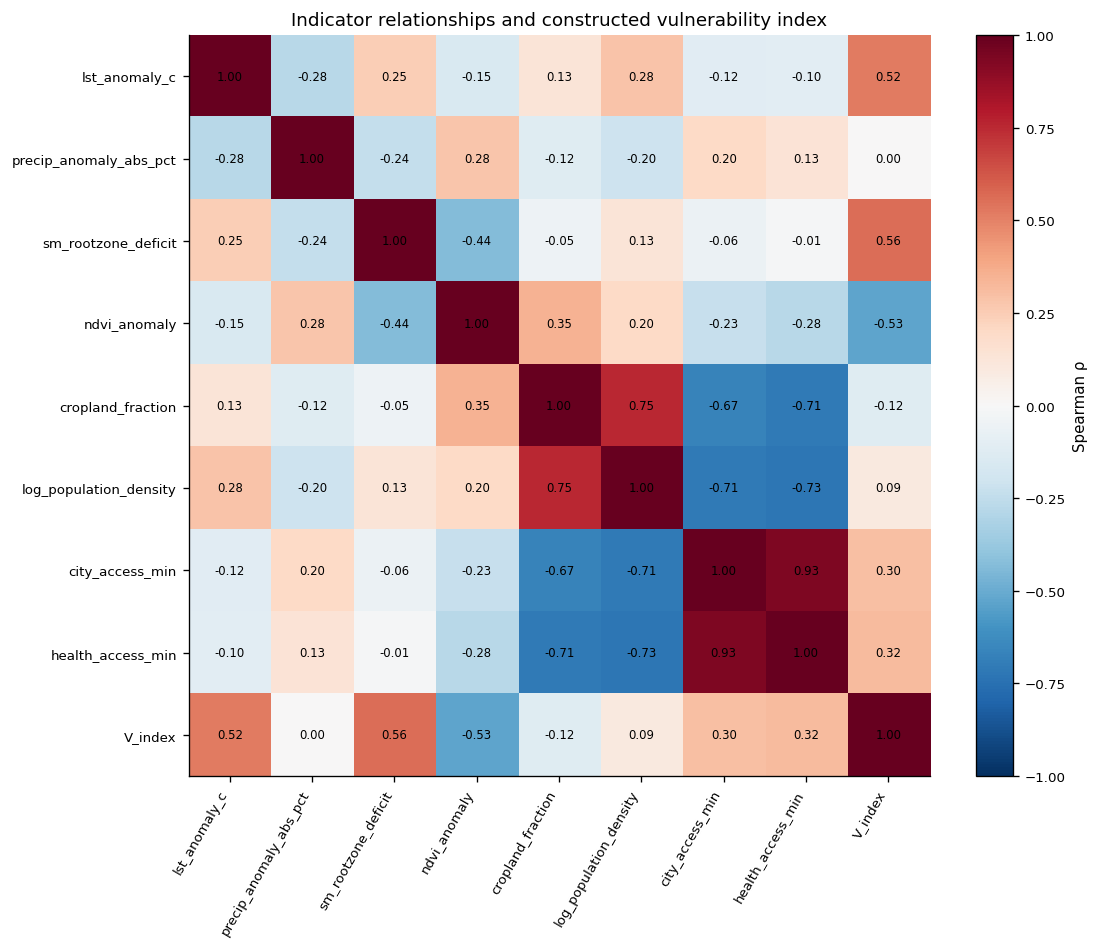

Correlation is diagnostic only. Tree models do not require predictor independence, and correlation must not be interpreted causally.


In [ ]:
ML_FEATURES = [
    "lst_anomaly_c",
    "precip_anomaly_abs_pct",
    "sm_rootzone_deficit",
    "ndvi_anomaly",
    "cropland_fraction",
    "log_population_density",
    "city_access_min",
    "health_access_min",
]
TARGET = "V_index"

corr = df[ML_FEATURES + [TARGET]].corr(method="spearman")
corr.to_csv(ROOT / "exports" / "spearman_indicator_correlation.csv")

fig, ax = plt.subplots(figsize=(9.2, 7.8), constrained_layout=True)
im = ax.imshow(corr, vmin=-1, vmax=1, cmap="RdBu_r")
ax.set_xticks(range(len(corr.columns)))
ax.set_xticklabels(corr.columns, rotation=60, ha="right")
ax.set_yticks(range(len(corr.index)))
ax.set_yticklabels(corr.index)
for i in range(len(corr.index)):
    for j in range(len(corr.columns)):
        ax.text(
            j, i, f"{corr.iloc[i, j]:.2f}",
            ha="center", va="center", fontsize=7
        )
fig.colorbar(im, ax=ax, label="Spearman ρ")
ax.set_title("Indicator relationships and constructed vulnerability index")
fig.savefig(
    ROOT / "figures" / "figS01_indicator_correlation.png",
    dpi=600, bbox_inches="tight"
)
fig.savefig(
    ROOT / "figures" / "figS01_indicator_correlation.pdf",
    bbox_inches="tight"
)
plt.show()
plt.close(fig)

print(
    "Correlation is diagnostic only. Tree models do not require predictor "
    "independence, and correlation must not be interpreted causally."
)

## 12. Publication-quality indicator, dimension, and vulnerability maps

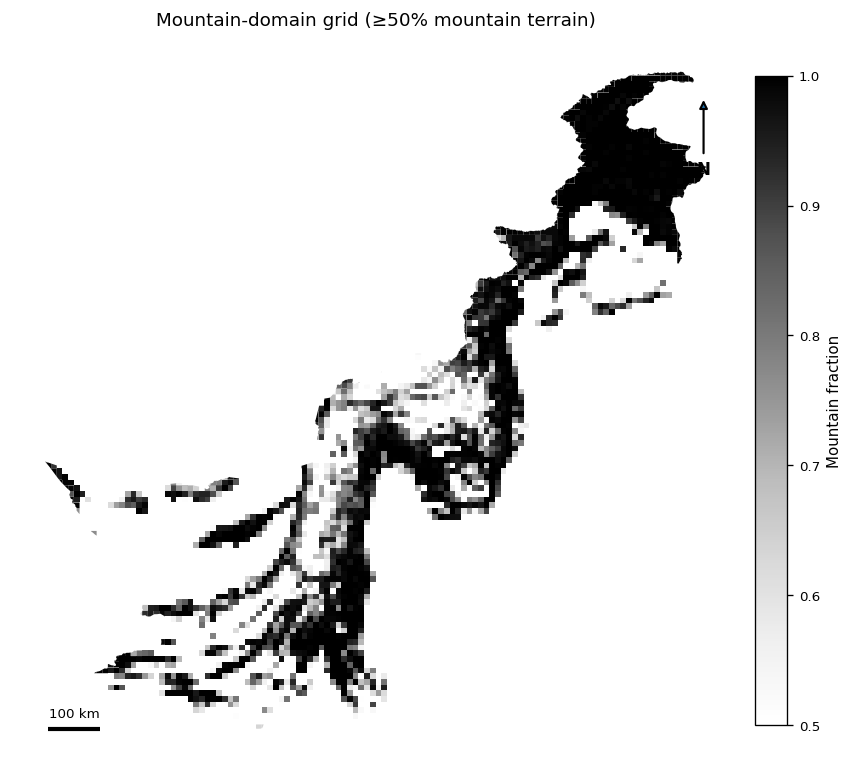

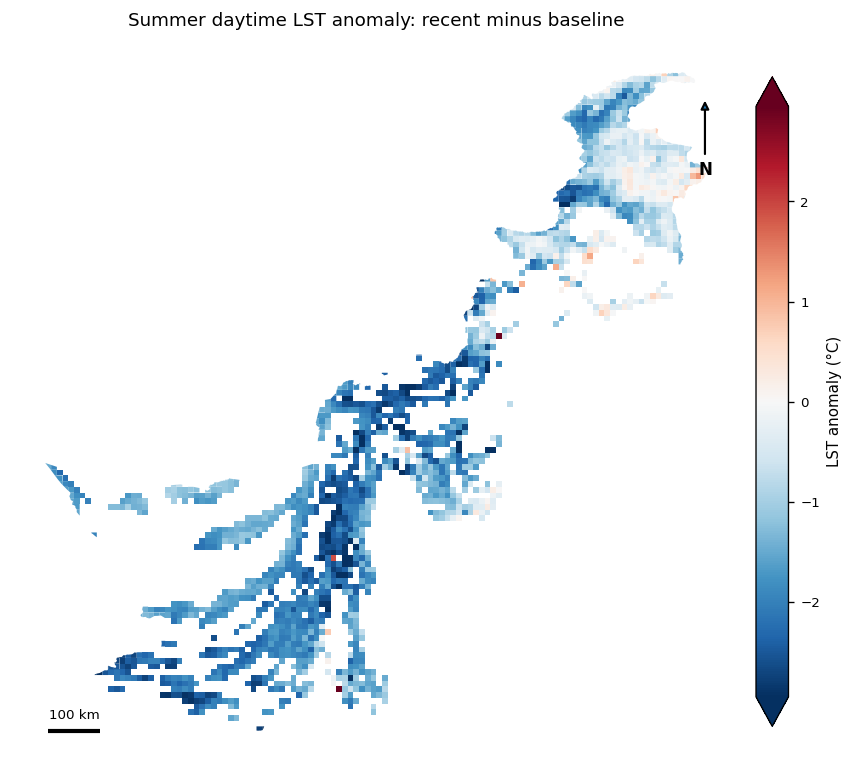

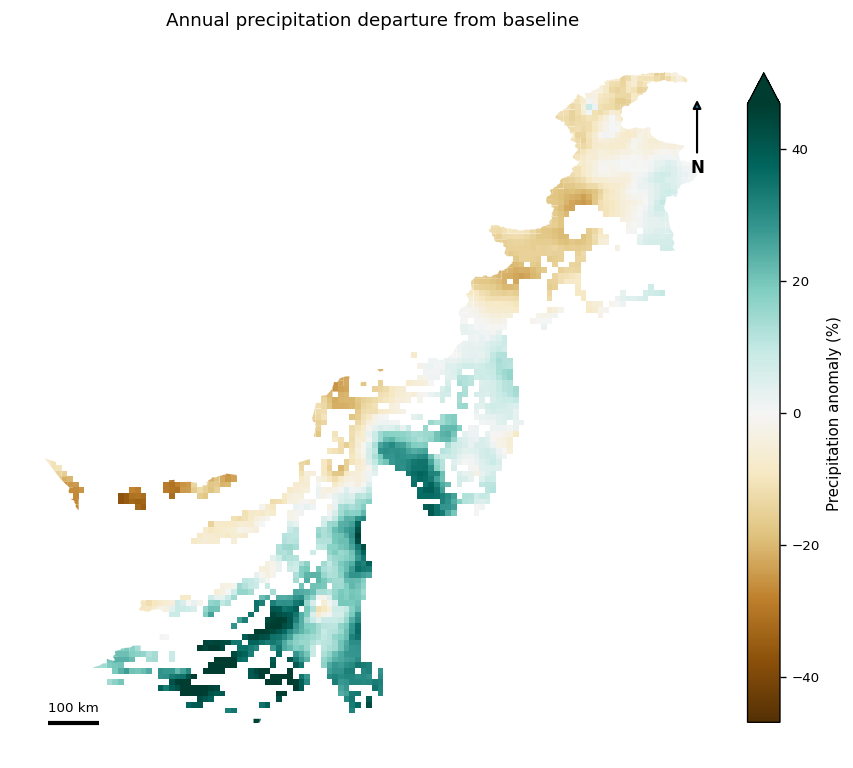

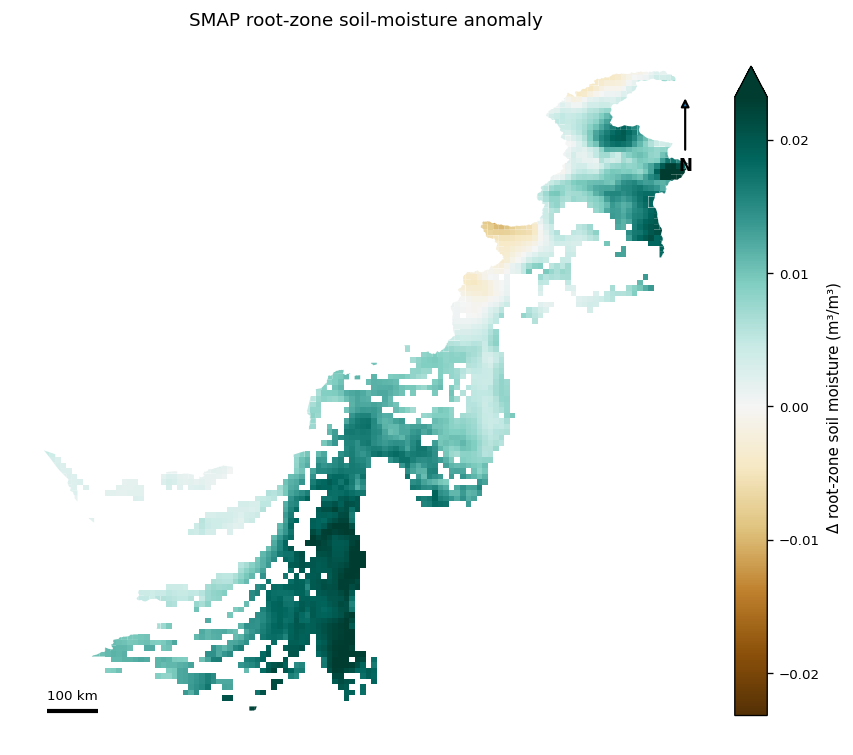

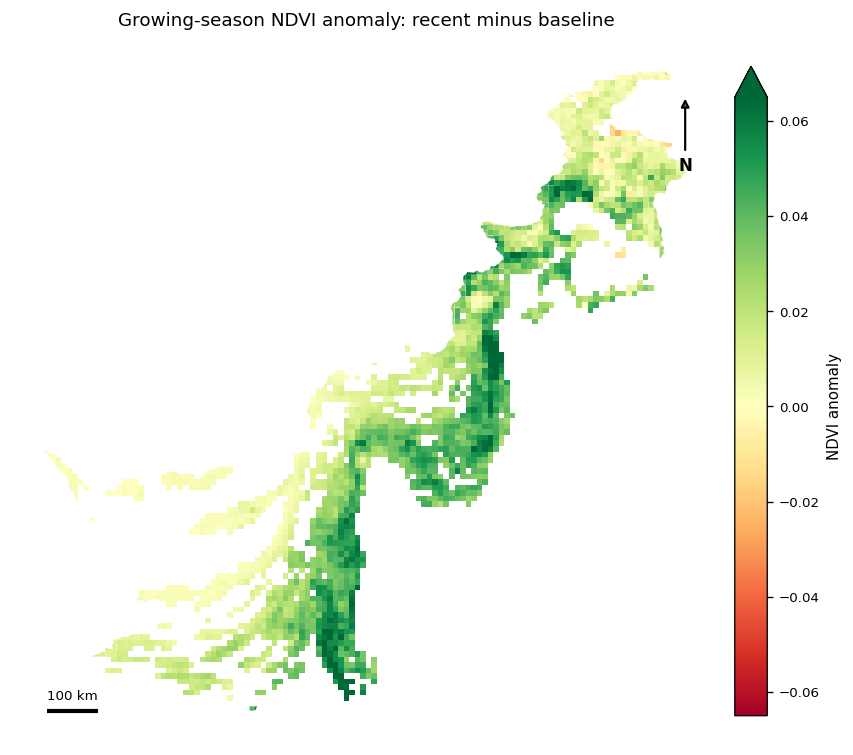

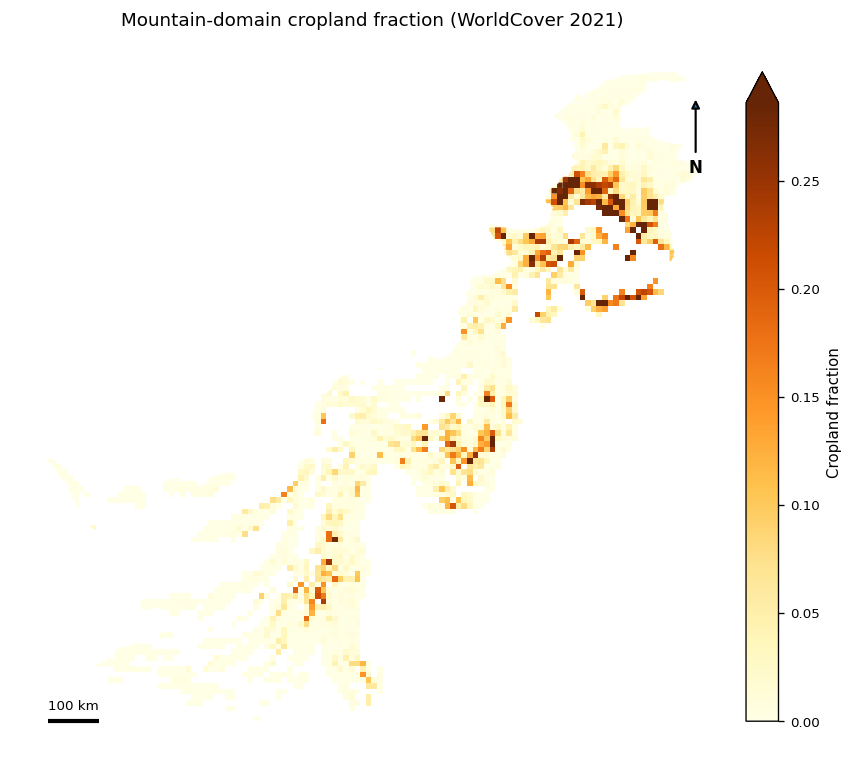

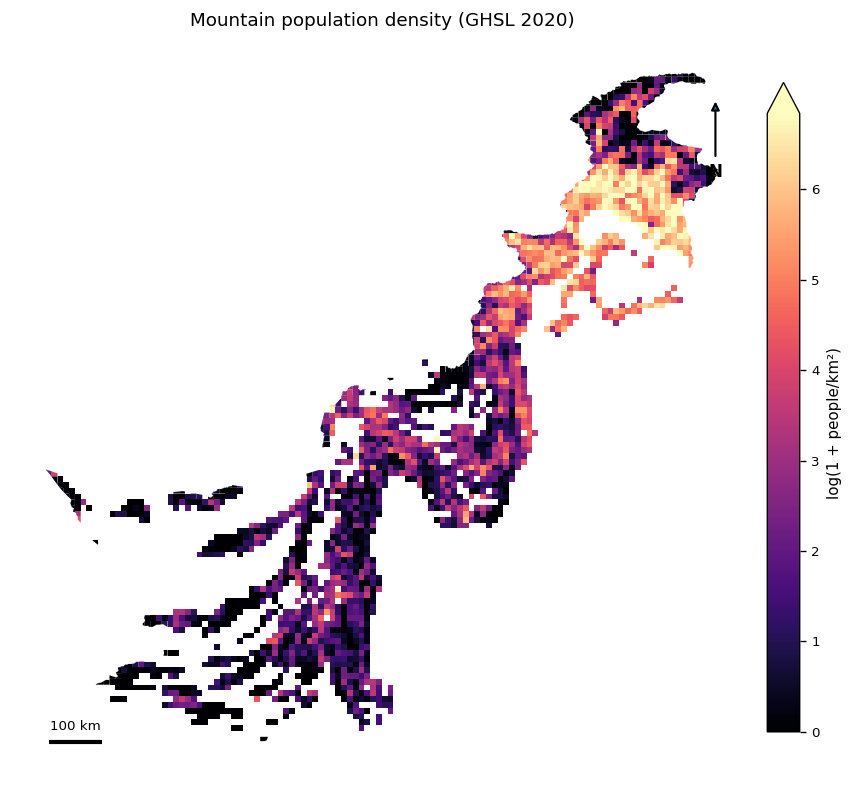

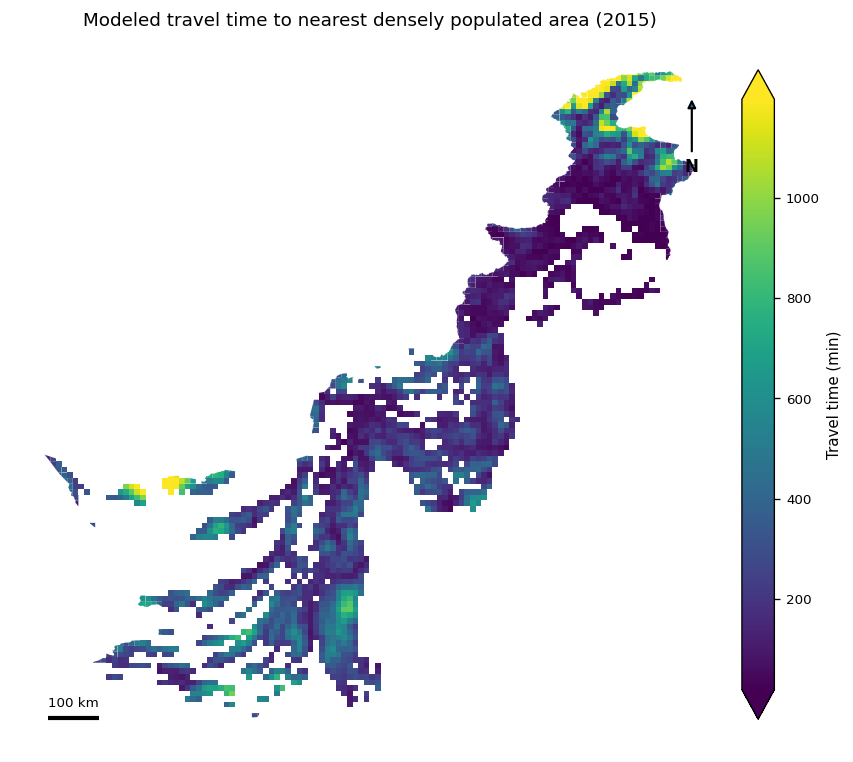

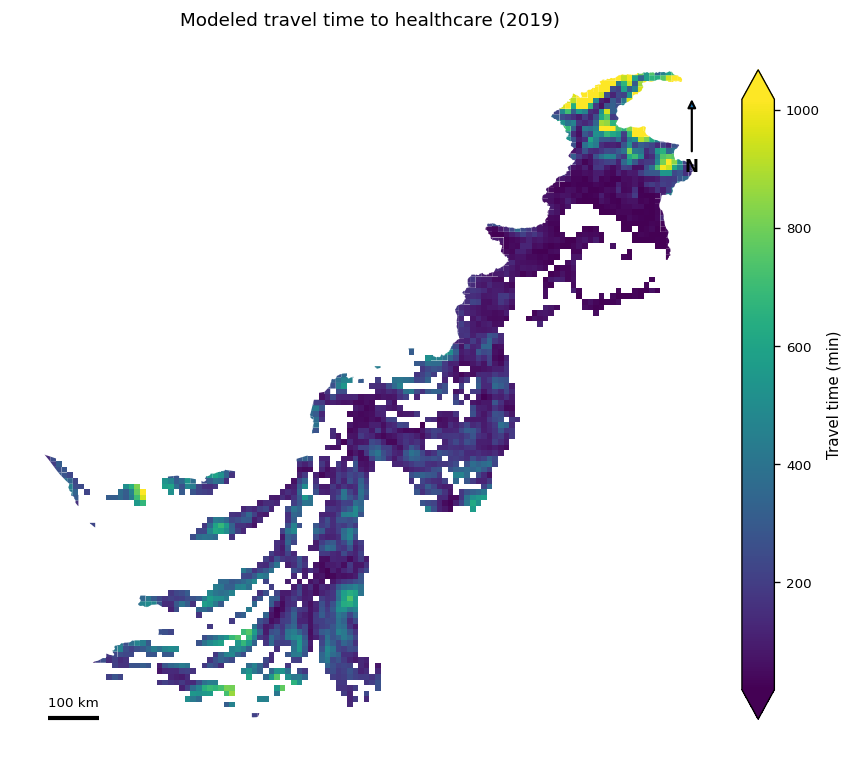

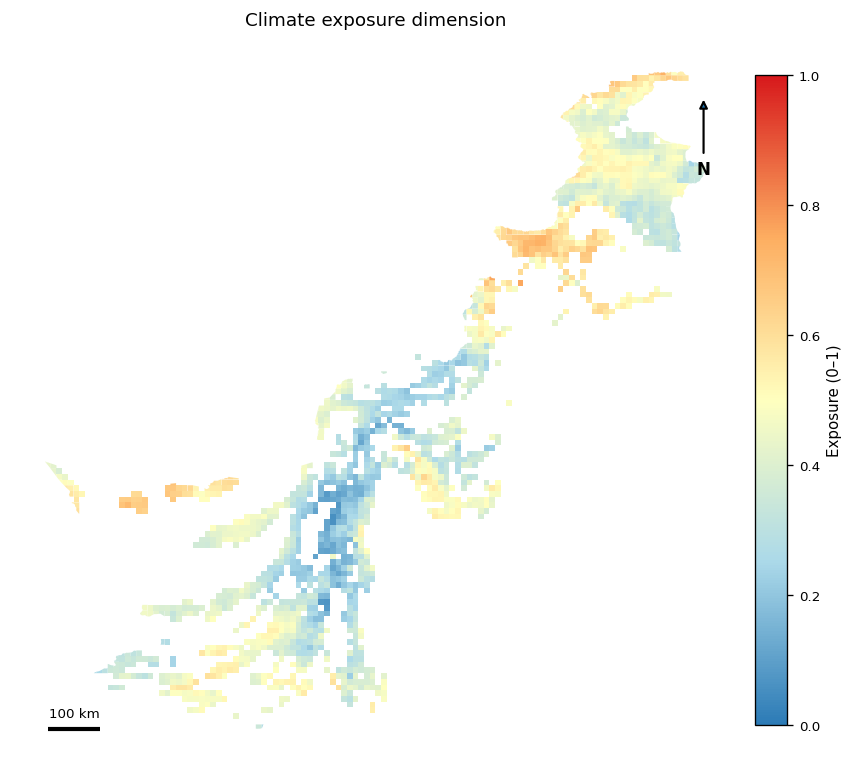

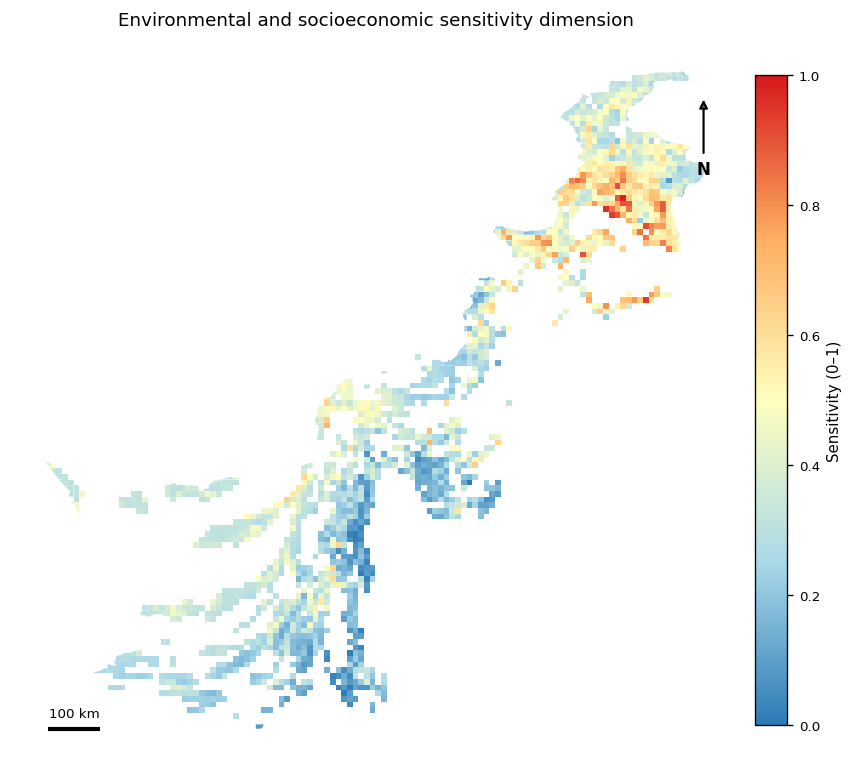

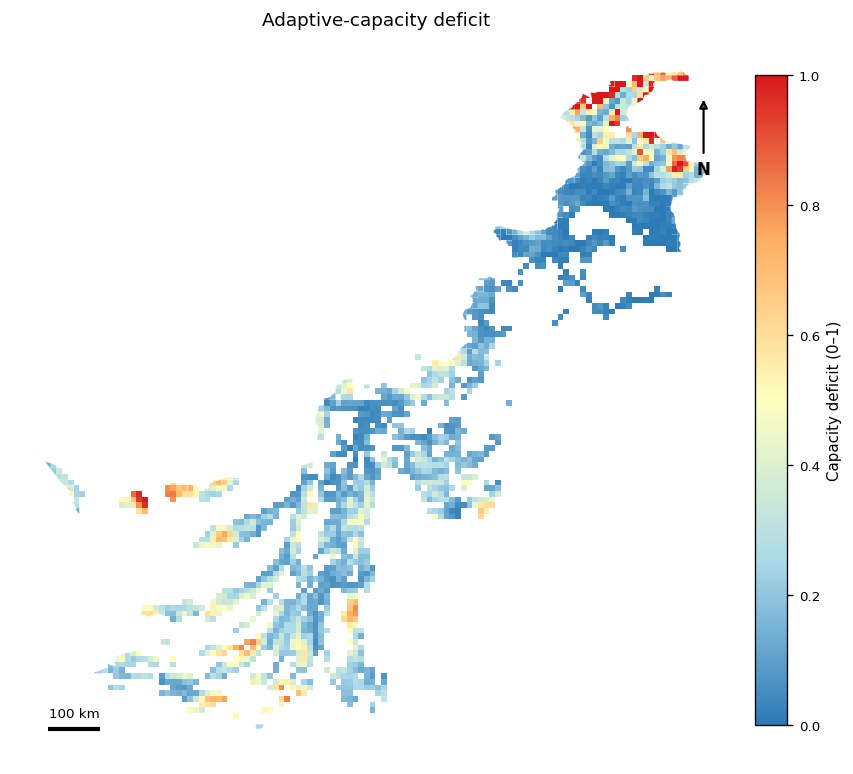

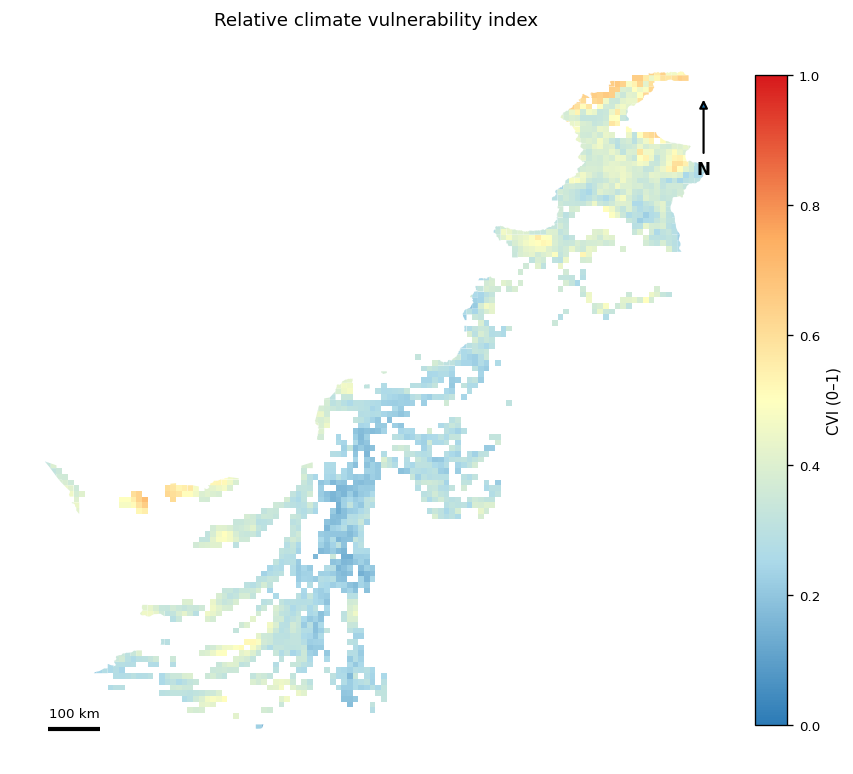

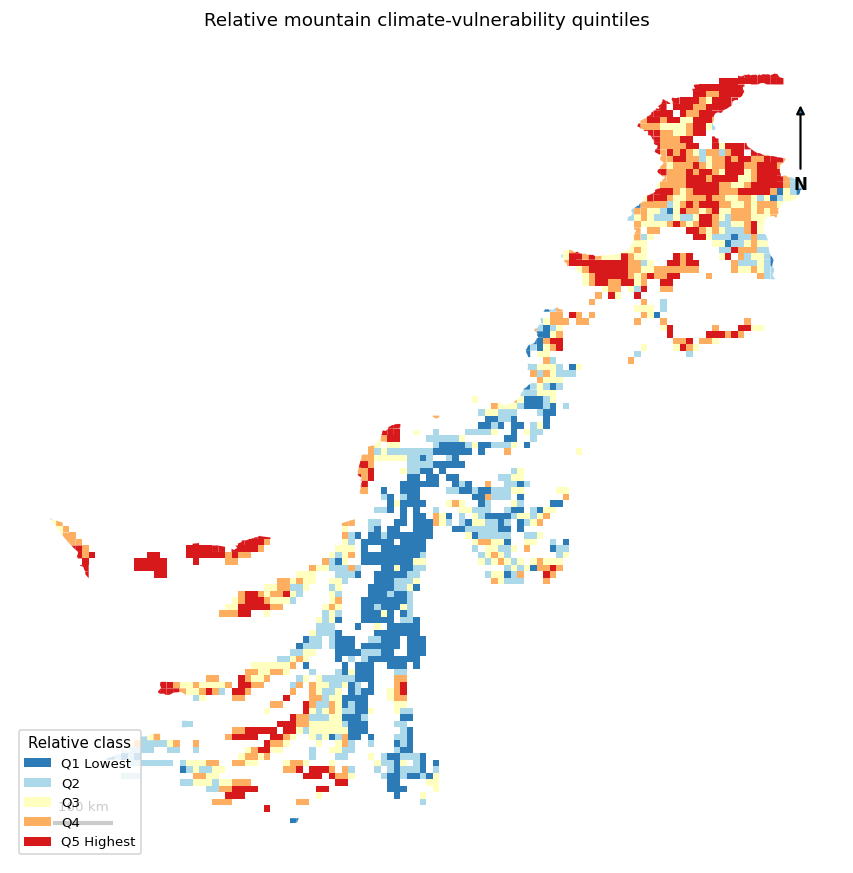

In [ ]:
VULN_CMAP = mpl.colors.LinearSegmentedColormap.from_list(
    "vulnerability",
    ["#2c7bb6", "#abd9e9", "#ffffbf", "#fdae61", "#d7191c"],
)
CLASS_COLORS = ["#2c7bb6", "#abd9e9", "#ffffbf", "#fdae61", "#d7191c"]

def robust_map_limits(series, symmetric=False, q=0.02):
    s = pd.to_numeric(series, errors="coerce").dropna()
    if len(s) == 0:
        raise ValueError("Cannot compute map limits from an empty series.")
    if symmetric:
        lim = max(abs(s.quantile(q)), abs(s.quantile(1 - q)))
        return -float(lim), float(lim)
    return float(s.quantile(q)), float(s.quantile(1 - q))

def add_map_decor(ax):
    xmin, xmax = ax.get_xlim()
    ymin, ymax = ax.get_ylim()
    ax.annotate(
        "N",
        xy=(0.95, 0.92),
        xytext=(0.95, 0.82),
        xycoords="axes fraction",
        arrowprops=dict(arrowstyle="-|>", lw=1.3),
        ha="center",
        va="center",
        fontsize=10,
        fontweight="bold",
    )
    x0 = xmin + 0.05 * (xmax - xmin)
    y0 = ymin + 0.045 * (ymax - ymin)
    length = 100_000
    ax.plot(
        [x0, x0 + length],
        [y0, y0],
        color="black",
        lw=2.5,
        solid_capstyle="butt",
    )
    ax.text(
        x0 + length / 2,
        y0 + 0.012 * (ymax - ymin),
        "100 km",
        ha="center",
        va="bottom",
        fontsize=8,
    )

def save_map(
    gdf_map,
    column,
    title,
    stem,
    cmap="viridis",
    legend_label=None,
    vmin=None,
    vmax=None,
):
    fig, ax = plt.subplots(figsize=(7.0, 7.6), constrained_layout=True)
    boundary_gdf.boundary.plot(
        ax=ax, color="black", linewidth=0.7, zorder=3
    )
    gdf_map.plot(
        column=column,
        ax=ax,
        cmap=cmap,
        vmin=vmin,
        vmax=vmax,
        linewidth=0,
        edgecolor="none",
        legend=True,
        legend_kwds={
            "label": legend_label,
            "shrink": 0.72,
            "pad": 0.02,
        } if legend_label else None,
    )
    ax.set_aspect("equal")
    ax.set_title(title, fontsize=11, pad=8)
    ax.set_axis_off()
    add_map_decor(ax)
    fig.savefig(
        ROOT / "figures" / f"{stem}.png",
        dpi=600, bbox_inches="tight"
    )
    fig.savefig(
        ROOT / "figures" / f"{stem}.pdf",
        bbox_inches="tight"
    )
    plt.show()
    plt.close(fig)

plot_cols = [
    "cell_id",
    "lst_recent_c",
    "lst_anomaly_c",
    "precip_anomaly_pct",
    "precip_anomaly_abs_pct",
    "sm_rootzone_anomaly",
    "sm_rootzone_deficit",
    "ndvi_recent",
    "ndvi_anomaly",
    "cropland_fraction",
    "population_density",
    "city_access_min",
    "health_access_min",
]
vuln_cols = [
    "cell_id",
    "Exposure",
    "Sensitivity",
    "AdaptiveCapacityDeficit",
    "V_index",
    "V_class_id",
    "V_class",
]

plot_grid = (
    grid
    .merge(df_all[plot_cols], on="cell_id", how="left", validate="one_to_one")
    .merge(df[vuln_cols], on="cell_id", how="left", validate="one_to_one")
)
plot_grid["log_population_density"] = np.log1p(
    plot_grid["population_density"].clip(lower=0)
)

save_map(
    plot_grid,
    "mountain_fraction",
    f"Mountain-domain grid (≥{CONFIG['MOUNTAIN_FRACTION_MIN']:.0%} mountain terrain)",
    "fig01_mountain_domain",
    cmap="Greys",
    legend_label="Mountain fraction",
    vmin=CONFIG["MOUNTAIN_FRACTION_MIN"],
    vmax=1,
)

lst_lim = robust_map_limits(plot_grid["lst_anomaly_c"], symmetric=True)
save_map(
    plot_grid.dropna(subset=["lst_anomaly_c"]),
    "lst_anomaly_c",
    "Summer daytime LST anomaly: recent minus baseline",
    "fig02_lst_anomaly",
    cmap="RdBu_r",
    legend_label="LST anomaly (°C)",
    vmin=lst_lim[0], vmax=lst_lim[1],
)

p_lim = robust_map_limits(plot_grid["precip_anomaly_pct"], symmetric=True)
save_map(
    plot_grid.dropna(subset=["precip_anomaly_pct"]),
    "precip_anomaly_pct",
    "Annual precipitation departure from baseline",
    "fig03_precip_anomaly",
    cmap="BrBG",
    legend_label="Precipitation anomaly (%)",
    vmin=p_lim[0], vmax=p_lim[1],
)

sm_lim = robust_map_limits(plot_grid["sm_rootzone_anomaly"], symmetric=True)
save_map(
    plot_grid.dropna(subset=["sm_rootzone_anomaly"]),
    "sm_rootzone_anomaly",
    "SMAP root-zone soil-moisture anomaly",
    "fig04_soil_moisture_anomaly",
    cmap="BrBG",
    legend_label="Δ root-zone soil moisture (m³/m³)",
    vmin=sm_lim[0], vmax=sm_lim[1],
)

ndvi_lim = robust_map_limits(plot_grid["ndvi_anomaly"], symmetric=True)
save_map(
    plot_grid.dropna(subset=["ndvi_anomaly"]),
    "ndvi_anomaly",
    "Growing-season NDVI anomaly: recent minus baseline",
    "fig05_ndvi_anomaly",
    cmap="RdYlGn",
    legend_label="NDVI anomaly",
    vmin=ndvi_lim[0], vmax=ndvi_lim[1],
)

crop_lim = robust_map_limits(plot_grid["cropland_fraction"])
save_map(
    plot_grid.dropna(subset=["cropland_fraction"]),
    "cropland_fraction",
    "Mountain-domain cropland fraction (WorldCover 2021)",
    "fig06_cropland_fraction",
    cmap="YlOrBr",
    legend_label="Cropland fraction",
    vmin=0, vmax=max(crop_lim[1], 0.05),
)

pop_lim = robust_map_limits(plot_grid["log_population_density"])
save_map(
    plot_grid.dropna(subset=["log_population_density"]),
    "log_population_density",
    f"Mountain population density (GHSL {CONFIG['POPULATION_YEAR']})",
    "fig07_population_density",
    cmap="magma",
    legend_label="log(1 + people/km²)",
    vmin=pop_lim[0], vmax=pop_lim[1],
)


city_lim = robust_map_limits(plot_grid["city_access_min"])
save_map(
    plot_grid.dropna(subset=["city_access_min"]),
    "city_access_min",
    "Modeled travel time to nearest densely populated area (2015)",
    "figS02_city_access",
    cmap="viridis",
    legend_label="Travel time (min)",
    vmin=city_lim[0], vmax=city_lim[1],
)

health_lim = robust_map_limits(plot_grid["health_access_min"])
save_map(
    plot_grid.dropna(subset=["health_access_min"]),
    "health_access_min",
    "Modeled travel time to healthcare (2019)",
    "fig08_health_access",
    cmap="viridis",
    legend_label="Travel time (min)",
    vmin=health_lim[0], vmax=health_lim[1],
)

save_map(
    plot_grid.dropna(subset=["Exposure"]),
    "Exposure",
    "Climate exposure dimension",
    "fig09_exposure",
    cmap=VULN_CMAP,
    legend_label="Exposure (0–1)",
    vmin=0, vmax=1,
)
save_map(
    plot_grid.dropna(subset=["Sensitivity"]),
    "Sensitivity",
    "Environmental and socioeconomic sensitivity dimension",
    "fig10_sensitivity",
    cmap=VULN_CMAP,
    legend_label="Sensitivity (0–1)",
    vmin=0, vmax=1,
)
save_map(
    plot_grid.dropna(subset=["AdaptiveCapacityDeficit"]),
    "AdaptiveCapacityDeficit",
    "Adaptive-capacity deficit",
    "fig11_adaptive_capacity_deficit",
    cmap=VULN_CMAP,
    legend_label="Capacity deficit (0–1)",
    vmin=0, vmax=1,
)
save_map(
    plot_grid.dropna(subset=["V_index"]),
    "V_index",
    "Relative climate vulnerability index",
    "fig12_vulnerability_continuous",
    cmap=VULN_CMAP,
    legend_label="CVI (0–1)",
    vmin=0, vmax=1,
)

from matplotlib.patches import Patch
class_cmap = mpl.colors.ListedColormap(CLASS_COLORS)

fig, ax = plt.subplots(figsize=(7.0, 7.6), constrained_layout=True)
boundary_gdf.boundary.plot(ax=ax, color="black", linewidth=0.7, zorder=3)
plot_grid.dropna(subset=["V_class_id"]).plot(
    column="V_class_id",
    ax=ax,
    cmap=class_cmap,
    vmin=0,
    vmax=4,
    linewidth=0,
    edgecolor="none",
)
legend_handles = [
    Patch(facecolor=CLASS_COLORS[i], edgecolor="none", label=lab)
    for i, lab in enumerate(
        ["Q1 Lowest", "Q2", "Q3", "Q4", "Q5 Highest"]
    )
]
ax.legend(
    handles=legend_handles,
    title="Relative class",
    loc="lower left",
    frameon=True,
)
ax.set_aspect("equal")
ax.set_title("Relative mountain climate-vulnerability quintiles", fontsize=11)
ax.set_axis_off()
add_map_decor(ax)
fig.savefig(
    ROOT / "figures" / "fig13_vulnerability_quintiles.png",
    dpi=600, bbox_inches="tight"
)
fig.savefig(
    ROOT / "figures" / "fig13_vulnerability_quintiles.pdf",
    bbox_inches="tight"
)
plt.show()
plt.close(fig)

## 13. Area, population, and cropland distribution by vulnerability class

            mountain_area_km2  mountain_area_pct  population_2020  \
V_class                                                             
Q1 Lowest            36897.46              19.41        419608.10   
Q2                   37653.21              19.81       2088706.44   
Q3                   38093.17              20.04       5019327.68   
Q4                   39267.98              20.66       8161212.33   
Q5 Highest           38197.56              20.09       7190268.99   

            cropland_area_km2  population_pct  
V_class                                        
Q1 Lowest              728.06            1.83  
Q2                     960.89            9.13  
Q3                    1279.33           21.94  
Q4                    2137.31           35.67  
Q5 Highest            1783.23           31.43  


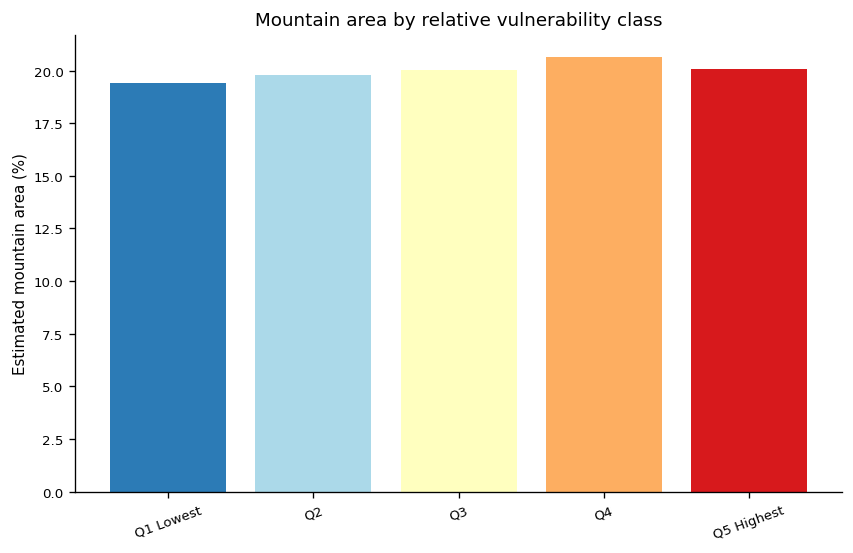

Interpretation note: population density and cropland fraction are CVI inputs, so their class-wise distributions are descriptive—not independent validation.


In [ ]:
class_order = ["Q1 Lowest", "Q2", "Q3", "Q4", "Q5 Highest"]

area_stats = (
    df.groupby("V_class")["mountain_area_km2"]
    .sum()
    .reindex(class_order)
    .rename("mountain_area_km2")
    .to_frame()
)
area_stats["mountain_area_pct"] = (
    100 * area_stats["mountain_area_km2"]
    / area_stats["mountain_area_km2"].sum()
)

pop_stats = (
    df.groupby("V_class")["population_sum"]
    .sum()
    .reindex(class_order)
    .rename(f"population_{CONFIG['POPULATION_YEAR']}")
)

crop_stats = (
    df.assign(
        cropland_area_km2=(
            df["cropland_fraction"] * df["mountain_area_km2"]
        )
    )
    .groupby("V_class")["cropland_area_km2"]
    .sum()
    .reindex(class_order)
)

exposure_table = pd.concat(
    [area_stats, pop_stats, crop_stats],
    axis=1,
)
exposure_table["population_pct"] = (
    100 * exposure_table[f"population_{CONFIG['POPULATION_YEAR']}"]
    / exposure_table[f"population_{CONFIG['POPULATION_YEAR']}"].sum()
)

exposure_table.to_csv(
    ROOT / "exports" / "mountain_area_population_cropland_by_class.csv"
)
print(exposure_table.round(2))

fig, ax = plt.subplots(figsize=(7, 4.5), constrained_layout=True)
ax.bar(
    exposure_table.index,
    exposure_table["mountain_area_pct"],
    color=CLASS_COLORS,
)
ax.set_ylabel("Estimated mountain area (%)")
ax.set_title("Mountain area by relative vulnerability class")
ax.tick_params(axis="x", rotation=20)
fig.savefig(
    ROOT / "figures" / "fig14_area_by_class.png",
    dpi=600, bbox_inches="tight"
)
fig.savefig(
    ROOT / "figures" / "fig14_area_by_class.pdf",
    bbox_inches="tight"
)
plt.show()
plt.close(fig)

print(
    "Interpretation note: population density and cropland fraction are CVI inputs, "
    "so their class-wise distributions are descriptive—not independent validation."
)

## 14. Descriptive annual climate/environmental context (no short-record trend claims)

   year  lst_summer_c  ndvi_growing   precip_mm  sm_rootzone
0  2016     26.627253      0.303161  517.777078     0.170361
1  2017     27.539031      0.287183  559.560403     0.159894
2  2018     27.528793      0.280631  514.899214     0.158652
3  2019     26.218768      0.306157  628.797976     0.178420
4  2020     26.605657      0.322173  663.862017     0.183620
5  2021     27.000534      0.297456  469.788113     0.161615
6  2022     25.858637      0.300497  533.907203     0.187629
7  2023     25.254388      0.321074  444.297203     0.174485
8  2024     24.772074      0.332030  572.500977     0.178369


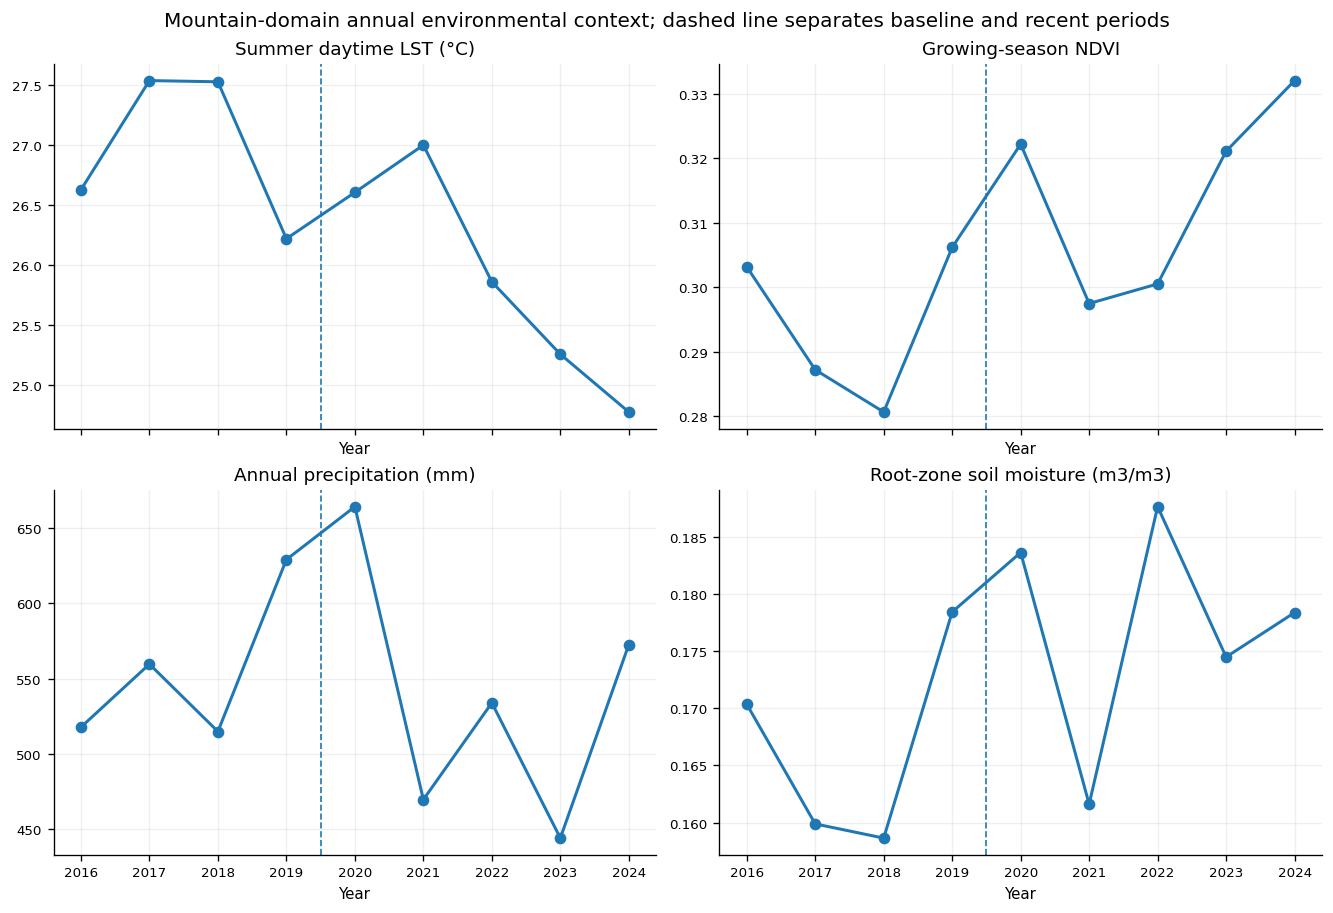

No Mann–Kendall or Sen-slope inference is reported: the common record contains only 9 complete calendar years.


In [ ]:
def mountain_annual_series(ic, band, scale):
    rows = []
    for year in YEARS:
        img = ee.Image(
            ic.filter(ee.Filter.eq("year", year)).first()
        ).updateMask(mountain_core)

        # Increase tileScale to 16 and use a slightly coarser scale to avoid memory limits
        val = (
            img.reduceRegion(
                reducer=ee.Reducer.mean(),
                geometry=study_geom,
                scale=max(float(scale), 10000.0), # Coarser scale for national diagnostic summary
                maxPixels=1e8,
                tileScale=16,
            )
            .get(band)
            .getInfo()
        )
        rows.append({"year": year, band: val})
    return pd.DataFrame(rows)

# LST and NDVI series via Earth Engine
annual_lst = mountain_annual_series(lst_yearly, "lst_summer_c", CONFIG["EE_MODIS_SCALE_M"])
annual_ndvi = mountain_annual_series(ndvi_yearly, "ndvi_growing", CONFIG["EE_MODIS_SCALE_M"])
annual_precip = mountain_annual_series(precip_yearly, "precip_mm", CONFIG["EE_CHIRPS_SCALE_M"])

# Compute SMAP annual series directly from the local `smap_monthly` DataFrame
# to bypass Earth Engine entirely and avoid memory issues.
annual_smap = (
    smap_monthly.groupby("year")["sm_rootzone_monthly"]
    .mean()
    .rename("sm_rootzone")
    .reset_index()
)

# Combine everything
annual = (
    annual_lst
    .merge(annual_ndvi, on="year")
    .merge(annual_precip, on="year")
    .merge(annual_smap, on="year")
)

annual.to_csv(
    ROOT / "exports" / "mountain_annual_series.csv",
    index=False,
)
print(annual)

fig, axes = plt.subplots(
    2, 2, figsize=(11, 7.5), sharex=True, constrained_layout=True
)
series_specs = [
    ("lst_summer_c", "Summer daytime LST (°C)"),
    ("ndvi_growing", "Growing-season NDVI"),
    ("precip_mm", "Annual precipitation (mm)"),
    ("sm_rootzone", "Root-zone soil moisture (m3/m3)"),
]

for ax, (col, label) in zip(axes.flat, series_specs):
    ax.plot(annual["year"], annual[col], marker="o", linewidth=1.8)
    ax.axvline(
        CONFIG["BASELINE_YEARS"][1] + 0.5,
        linestyle="--",
        linewidth=1,
    )
    ax.set_title(label)
    ax.grid(alpha=0.2)
    ax.set_xlabel("Year")

fig.suptitle(
    "Mountain-domain annual environmental context; dashed line separates baseline and recent periods",
    fontsize=12,
)
fig.savefig(
    ROOT / "figures" / "fig15_annual_context.png",
    dpi=600, bbox_inches="tight"
)
fig.savefig(
    ROOT / "figures" / "fig15_annual_context.pdf",
    bbox_inches="tight"
)
plt.show()
plt.close(fig)

print(
    "No Mann–Kendall or Sen-slope inference is reported: the common record "
    f"contains only {len(YEARS)} complete calendar years."
)

             indicator                                    label     n    mean  \
0        lst_anomaly_c          Summer daytime LST anomaly (°C)  1975 -1.4637   
1   precip_anomaly_pct       Annual precipitation departure (%)  2250  4.8214   
2  sm_rootzone_anomaly  Root-zone soil-moisture anomaly (m³/m³)  2349  0.0104   
3         ndvi_anomaly              Growing-season NDVI anomaly  2317  0.0250   

       std      q05     q25  median      q75      q95  
0   0.9103  -2.6920 -2.0794 -1.5624  -0.8719   0.0300  
1  18.0168 -19.1636 -8.6517  1.8199  15.8517  39.1232  
2   0.0072  -0.0011  0.0048  0.0101   0.0163   0.0216  
3   0.0188   0.0010  0.0088  0.0227   0.0392   0.0567  


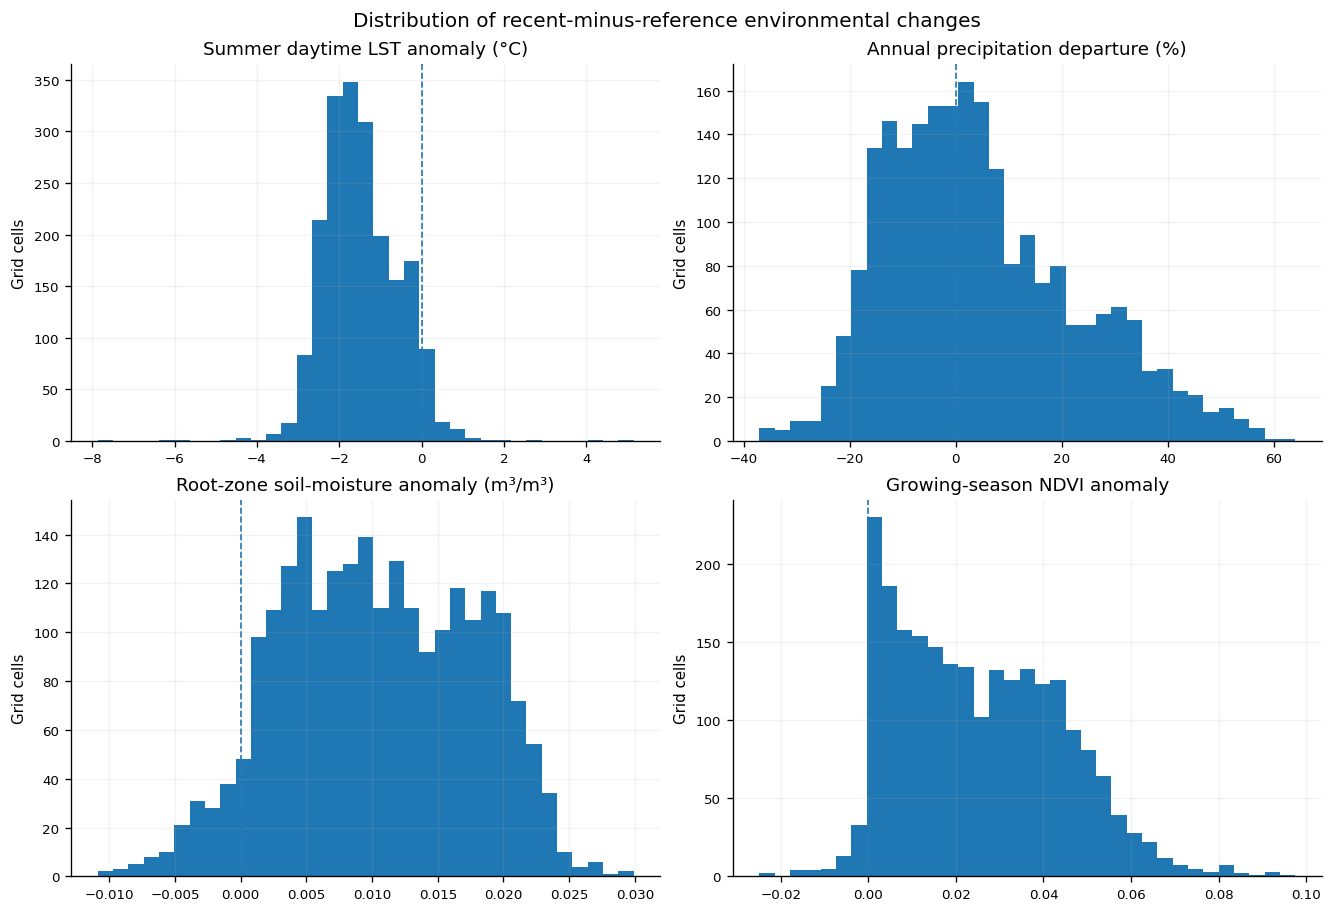

These are short-period spatial departures, not inferential climate trends.


In [ ]:
change_vars = {
    "lst_anomaly_c": "Summer daytime LST anomaly (°C)",
    "precip_anomaly_pct": "Annual precipitation departure (%)",
    "sm_rootzone_anomaly": "Root-zone soil-moisture anomaly (m³/m³)",
    "ndvi_anomaly": "Growing-season NDVI anomaly",
}

summary_rows = []
for col, label in change_vars.items():
    s = pd.to_numeric(df_all[col], errors="coerce").dropna()
    summary_rows.append({
        "indicator": col,
        "label": label,
        "n": len(s),
        "mean": s.mean(),
        "std": s.std(),
        "q05": s.quantile(.05),
        "q25": s.quantile(.25),
        "median": s.median(),
        "q75": s.quantile(.75),
        "q95": s.quantile(.95),
    })

period_change_summary = pd.DataFrame(summary_rows)
period_change_summary.to_csv(
    ROOT / "exports" / "period_change_summary.csv",
    index=False,
)
print(period_change_summary.round(4))

fig, axes = plt.subplots(
    2, 2, figsize=(11, 7.5), constrained_layout=True
)
for ax, (col, label) in zip(axes.flat, change_vars.items()):
    values = pd.to_numeric(df_all[col], errors="coerce").dropna()
    ax.hist(values, bins=35)
    ax.axvline(0, linestyle="--", linewidth=1)
    ax.set_title(label)
    ax.set_ylabel("Grid cells")
    ax.grid(alpha=0.15)

fig.suptitle(
    "Distribution of recent-minus-reference environmental changes",
    fontsize=12,
)
fig.savefig(
    ROOT / "figures" / "fig15_period_change_distributions.png",
    dpi=600, bbox_inches="tight"
)
fig.savefig(
    ROOT / "figures" / "fig15_period_change_distributions.pdf",
    bbox_inches="tight"
)
plt.show()
plt.close(fig)

print(
    "These are short-period spatial departures, not inferential climate trends."
)


## 15. Random Forest and XGBoost surrogate modelling with spatial cross-validation

The ML target is the constructed `V_index`. The same eight substantive indicators that define the CVI are used as predictors in their pre-index form. Consequently:

- ML performance evaluates **reproduction/generalization of the index**.
- It is not external validation against observed impacts or losses.
- Spatial folds are defined by K-means clustering of equal-area grid centroids into broad geographic regions; GroupKFold then leaves one region out at a time.
- Random 5-fold CV is retained only as an optimism diagnostic.

Spatial fold sizes:
spatial_fold
0    472
1    428
2    267
3    449
4    226
Name: n_cells, dtype: int64

RandomForest: random 5-fold OOF
fold 1: train=1,473, valid=369
fold 2: train=1,473, valid=369
fold 3: train=1,474, valid=368
fold 4: train=1,474, valid=368
fold 5: train=1,474, valid=368
RandomForest: spatial grouped OOF
fold 1: train=1,370, valid=472
fold 2: train=1,393, valid=449
fold 3: train=1,414, valid=428
fold 4: train=1,575, valid=267
fold 5: train=1,616, valid=226

XGBoost: random 5-fold OOF
fold 1: train=1,473, valid=369
fold 2: train=1,473, valid=369
fold 3: train=1,474, valid=368
fold 4: train=1,474, valid=368
fold 5: train=1,474, valid=368
XGBoost: spatial grouped OOF
fold 1: train=1,370, valid=472
fold 2: train=1,393, valid=449
fold 3: train=1,414, valid=428
fold 4: train=1,575, valid=267
fold 5: train=1,616, valid=226
          model            split     n    RMSE     MAE      R2  Spearman_rho
0  RandomForest     random_5fold  1842  0.0210  0.0162  0.9498        0.9

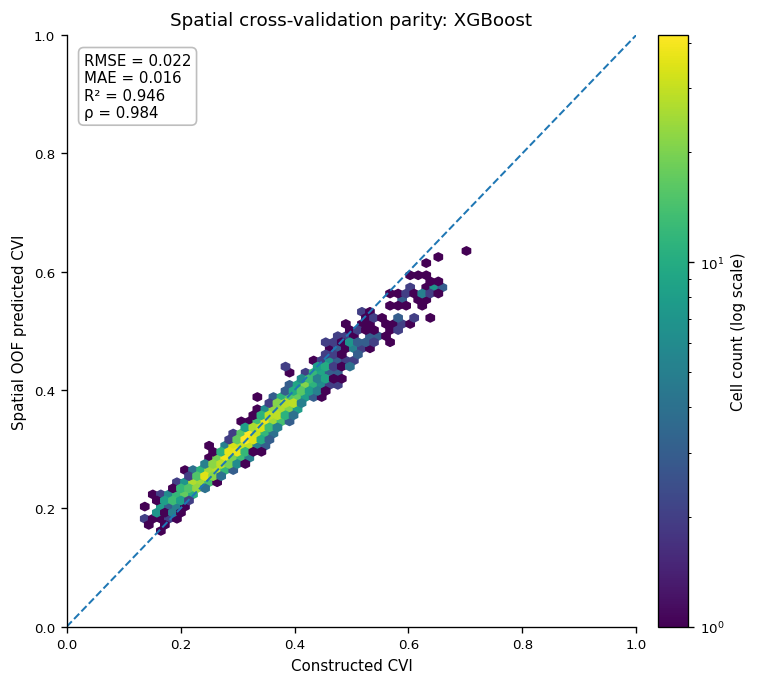

In [ ]:
ml = df.dropna(subset=ML_FEATURES + [TARGET]).copy()
X = ml[ML_FEATURES].astype(float).copy()
y = ml[TARGET].astype(float).copy()

if len(ml) < 100:
    raise RuntimeError("Too few complete cells for the planned ML analysis.")

n_spatial = min(CONFIG["N_SPATIAL_FOLDS"], len(ml))
if n_spatial < 3:
    raise RuntimeError("At least three spatial folds are required.")

coords = ml[["centroid_x_m", "centroid_y_m"]].to_numpy()
clusterer = KMeans(
    n_clusters=n_spatial,
    random_state=CONFIG["RANDOM_SEED"],
    n_init=20,
)
ml["spatial_fold"] = clusterer.fit_predict(coords)
groups = ml["spatial_fold"]

fold_sizes = ml.groupby("spatial_fold").size().rename("n_cells")
print("Spatial fold sizes:")
print(fold_sizes)

rf = RandomForestRegressor(
    n_estimators=500,
    max_depth=None,
    min_samples_leaf=3,
    max_features=0.8,
    random_state=CONFIG["RANDOM_SEED"],
    n_jobs=-1,
)

xgb = XGBRegressor(
    n_estimators=600,
    max_depth=4,
    learning_rate=0.03,
    subsample=0.8,
    colsample_bytree=0.8,
    min_child_weight=3,
    reg_lambda=1.0,
    reg_alpha=0.05,
    objective="reg:squarederror",
    random_state=CONFIG["RANDOM_SEED"],
    tree_method="hist",
    n_jobs=-1,
)

def oof_predictions(model, X, y, splitter, groups=None):
    pred = np.full(len(X), np.nan, dtype=float)
    for fold, (train_idx, val_idx) in enumerate(
        splitter.split(X, y, groups)
    ):
        m = clone(model)
        m.fit(X.iloc[train_idx], y.iloc[train_idx])
        pred[val_idx] = np.clip(
            m.predict(X.iloc[val_idx]), 0, 1
        )
        print(
            f"fold {fold + 1}: train={len(train_idx):,}, "
            f"valid={len(val_idx):,}"
        )
    return pred

def regression_metrics(y_true, pred, model_name, split_name):
    mask = np.isfinite(pred)
    yt = np.asarray(y_true)[mask]
    yp = np.asarray(pred)[mask]
    rho = spearmanr(yt, yp).statistic
    return {
        "model": model_name,
        "split": split_name,
        "n": len(yt),
        "RMSE": float(np.sqrt(mean_squared_error(yt, yp))),
        "MAE": float(mean_absolute_error(yt, yp)),
        "R2": float(r2_score(yt, yp)),
        "Spearman_rho": float(rho),
    }

random_cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=CONFIG["RANDOM_SEED"],
)
spatial_cv = GroupKFold(n_splits=n_spatial)

pred_store = {}
metrics = []

for name, model in [("RandomForest", rf), ("XGBoost", xgb)]:
    print(f"\n{name}: random 5-fold OOF")
    p_random = oof_predictions(model, X, y, random_cv)

    print(f"{name}: spatial grouped OOF")
    p_spatial = oof_predictions(
        model, X, y, spatial_cv, groups=groups
    )

    metrics.append(
        regression_metrics(y, p_random, name, "random_5fold")
    )
    metrics.append(
        regression_metrics(y, p_spatial, name, "spatial_grouped")
    )
    pred_store[name] = {
        "random": p_random,
        "spatial": p_spatial,
    }

metrics_df = pd.DataFrame(metrics)
metrics_df.to_csv(
    ROOT / "exports" / "ml_metrics.csv",
    index=False,
)
print(metrics_df.round(4))

rf_final = clone(rf).fit(X, y)
xgb_final = clone(xgb).fit(X, y)

import joblib
joblib.dump(
    rf_final,
    ROOT / "models" / "random_forest_cvi_surrogate.joblib",
)
joblib.dump(
    xgb_final,
    ROOT / "models" / "xgboost_cvi_surrogate.joblib",
)

best_name = (
    metrics_df.query("split == 'spatial_grouped'")
    .sort_values("RMSE", ascending=True)["model"]
    .iloc[0]
)
best_spatial_pred = pred_store[best_name]["spatial"]

fig, ax = plt.subplots(figsize=(6.2, 5.6), constrained_layout=True)
mask = np.isfinite(best_spatial_pred)
hb = ax.hexbin(
    y.values[mask],
    best_spatial_pred[mask],
    gridsize=40,
    mincnt=1,
    bins="log",
)
ax.plot([0, 1], [0, 1], linestyle="--", linewidth=1.2)
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.set_xlabel("Constructed CVI")
ax.set_ylabel("Spatial OOF predicted CVI")
ax.set_title(f"Spatial cross-validation parity: {best_name}")
fig.colorbar(hb, ax=ax, pad=0.02, label="Cell count (log scale)")

mrow = metrics_df.query(
    "model == @best_name and split == 'spatial_grouped'"
).iloc[0]
ax.text(
    0.03,
    0.97,
    (
        f"RMSE = {mrow.RMSE:.3f}\n"
        f"MAE = {mrow.MAE:.3f}\n"
        f"R² = {mrow.R2:.3f}\n"
        f"ρ = {mrow.Spearman_rho:.3f}"
    ),
    transform=ax.transAxes,
    va="top",
    ha="left",
    bbox=dict(
        boxstyle="round,pad=0.35",
        facecolor="white",
        alpha=0.85,
        edgecolor="0.7",
    ),
)
fig.savefig(
    ROOT / "figures" / "fig16_ml_spatial_parity.png",
    dpi=600, bbox_inches="tight"
)
fig.savefig(
    ROOT / "figures" / "fig16_ml_spatial_parity.pdf",
    bbox_inches="tight"
)
plt.show()
plt.close(fig)

## 16. Feature importance and SHAP interpretation

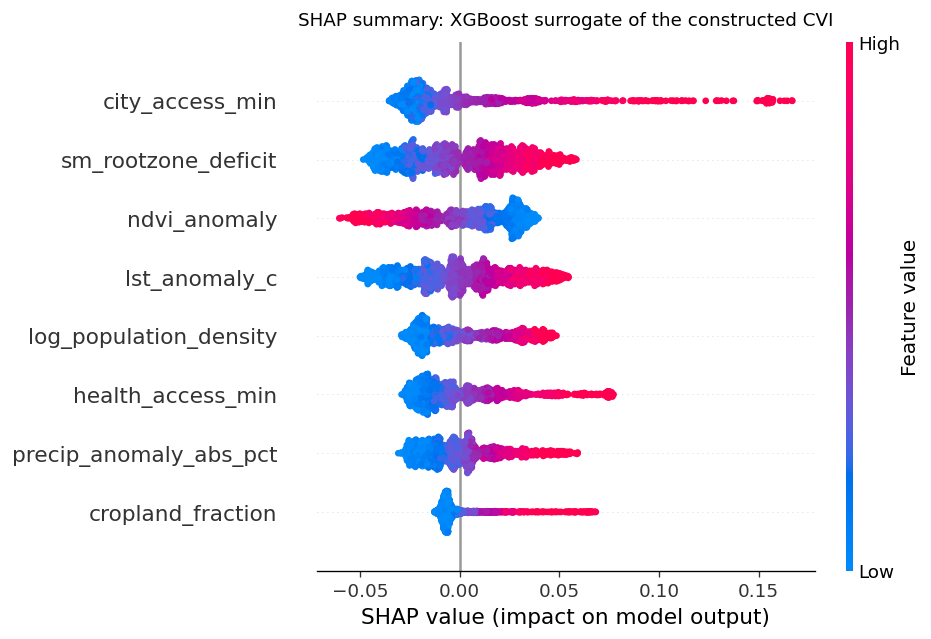

                  feature  mean_abs_shap  relative_importance
6         city_access_min       0.026528             0.170515
2     sm_rootzone_deficit       0.022959             0.147575
3            ndvi_anomaly       0.022773             0.146383
0           lst_anomaly_c       0.020949             0.134657
5  log_population_density       0.019272             0.123875
7       health_access_min       0.018325             0.117792
1  precip_anomaly_abs_pct       0.015151             0.097386
4       cropland_fraction       0.009617             0.061818
SHAP values explain XGBoost predictions of a constructed index. They are not causal effects and do not establish independent indicator validity.


In [ ]:
feature_importance = pd.DataFrame({
    "feature": ML_FEATURES,
    "RF_MDI": rf_final.feature_importances_,
    "XGB_gain": xgb_final.feature_importances_,
})
feature_importance.to_csv(
    ROOT / "exports" / "tree_feature_importance.csv",
    index=False,
)

# SHAP is computed for XGBoost because TreeSHAP is efficient for tree ensembles.
X_shap = X.sample(
    min(2500, len(X)),
    random_state=CONFIG["RANDOM_SEED"],
)

explainer = shap.TreeExplainer(xgb_final)
shap_values = explainer.shap_values(X_shap)
shap_values = np.asarray(shap_values)

shap.summary_plot(
    shap_values,
    X_shap,
    show=False,
    plot_size=(8.0, 5.4),
    max_display=len(ML_FEATURES),
)
plt.title(
    "SHAP summary: XGBoost surrogate of the constructed CVI",
    pad=10,
)
plt.tight_layout()
plt.savefig(
    ROOT / "figures" / "fig17_shap_summary.png",
    dpi=600, bbox_inches="tight"
)
plt.savefig(
    ROOT / "figures" / "fig17_shap_summary.pdf",
    bbox_inches="tight"
)
plt.show()
plt.close()

mean_abs_shap = np.abs(shap_values).mean(axis=0)
shap_table = (
    pd.DataFrame({
        "feature": X_shap.columns,
        "mean_abs_shap": mean_abs_shap,
    })
    .sort_values("mean_abs_shap", ascending=False)
)
shap_table["relative_importance"] = (
    shap_table["mean_abs_shap"]
    / shap_table["mean_abs_shap"].sum()
)
shap_table.to_csv(
    ROOT / "exports" / "shap_global_importance_xgboost.csv",
    index=False,
)
print(shap_table)

print(
    "SHAP values explain XGBoost predictions of a constructed index. "
    "They are not causal effects and do not establish independent indicator validity."
)

## 17. Full-grid surrogate prediction and spatial OOF residual diagnostics

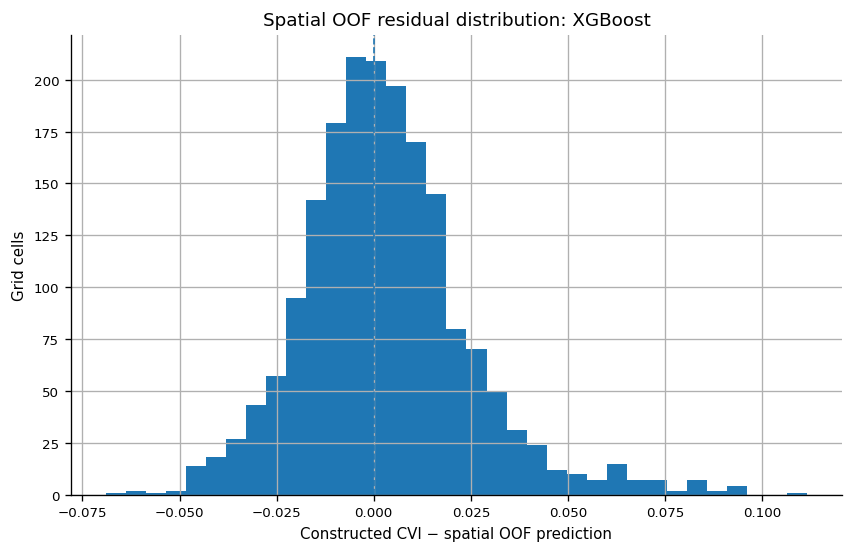

In [ ]:
final_model = rf_final if best_name == "RandomForest" else xgb_final
final_model_name = best_name

predict_mask = df[ML_FEATURES].notna().all(axis=1)
df["surrogate_V"] = np.nan
df.loc[predict_mask, "surrogate_V"] = np.clip(
    final_model.predict(df.loc[predict_mask, ML_FEATURES]),
    0, 1,
)
df["surrogate_residual_fullfit"] = (
    df[TARGET] - df["surrogate_V"]
)

ml["spatial_oof_prediction"] = best_spatial_pred
ml["spatial_oof_residual"] = (
    ml[TARGET] - ml["spatial_oof_prediction"]
)
ml["spatial_oof_abs_error"] = ml["spatial_oof_residual"].abs()

df = df.merge(
    ml[[
        "cell_id",
        "spatial_fold",
        "spatial_oof_prediction",
        "spatial_oof_residual",
        "spatial_oof_abs_error",
    ]],
    on="cell_id",
    how="left",
    validate="one_to_one",
)

grid_pred = grid.merge(
    df[[
        "cell_id",
        TARGET,
        "surrogate_V",
        "surrogate_residual_fullfit",
        "spatial_fold",
        "spatial_oof_prediction",
        "spatial_oof_residual",
        "spatial_oof_abs_error",
    ]],
    on="cell_id",
    how="left",
    validate="one_to_one",
)

grid_pred.to_file(
    ROOT / "exports" / "vulnerability_and_ml_diagnostics.geojson",
    driver="GeoJSON",
)
df.to_parquet(
    ROOT / "processed" / "final_grid_results.parquet",
    index=False,
)

fig, ax = plt.subplots(figsize=(7, 4.5), constrained_layout=True)
df["spatial_oof_residual"].dropna().hist(ax=ax, bins=35)
ax.axvline(0, linestyle="--", linewidth=1)
ax.set_xlabel("Constructed CVI − spatial OOF prediction")
ax.set_ylabel("Grid cells")
ax.set_title(
    f"Spatial OOF residual distribution: {final_model_name}"
)
fig.savefig(
    ROOT / "figures" / "fig18_spatial_oof_residuals.png",
    dpi=600, bbox_inches="tight"
)
fig.savefig(
    ROOT / "figures" / "fig18_spatial_oof_residuals.pdf",
    bbox_inches="tight"
)
plt.show()
plt.close(fig)

## 18. Spatial hotspot analysis of the continuous CVI

Queen contiguity produced 7 islands; using 8-nearest-neighbor weights for a connected mountain graph.
FDR-corrected hotspots: 294
FDR-corrected coldspots: 387


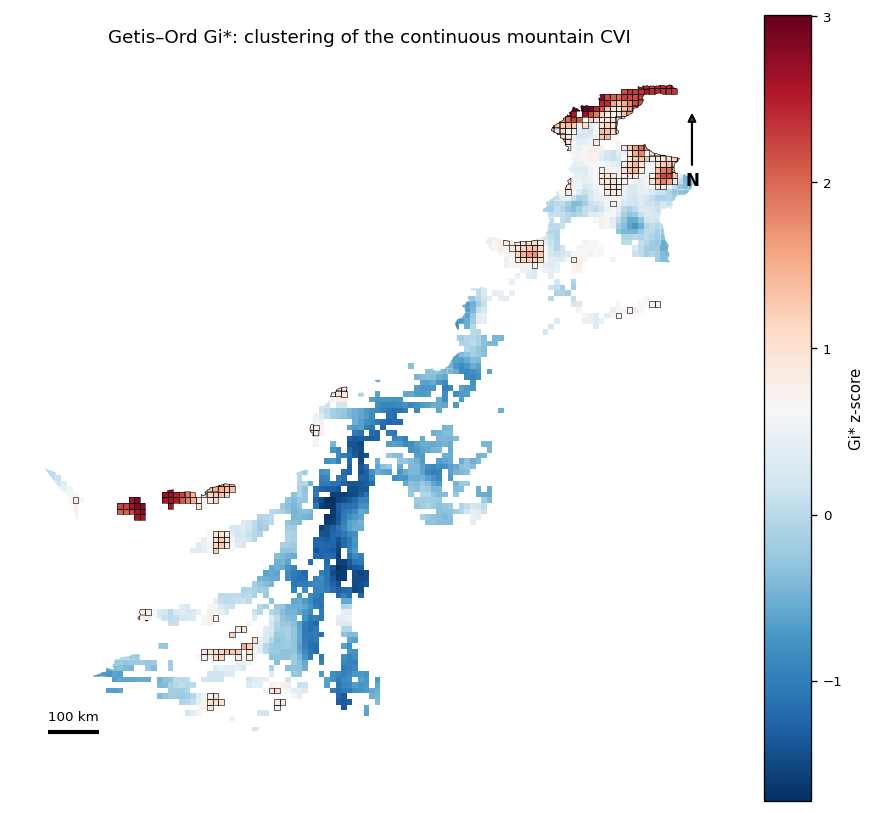

In [ ]:
from shapely.geometry import Polygon, MultiPolygon

hot = grid_pred.dropna(subset=[TARGET]).copy().reset_index(drop=True)
if len(hot) < 50:
    raise RuntimeError("Too few valid cells for hotspot analysis.")

def keep_only_polygons(geom):
    if geom.geom_type in ["Polygon", "MultiPolygon"]:
        return geom
    if geom.geom_type == "GeometryCollection":
        polys = [
            g for g in geom.geoms
            if g.geom_type in ["Polygon", "MultiPolygon"]
        ]
        if len(polys) == 1:
            return polys[0]
        if len(polys) > 1:
            return MultiPolygon(polys)
    return geom

hot["geometry"] = hot["geometry"].apply(keep_only_polygons)
hot = hot[
    hot.geometry.geom_type.isin(["Polygon", "MultiPolygon"])
].copy().reset_index(drop=True)

queen = Queen.from_dataframe(hot, use_index=False)
if len(queen.islands) > 0:
    k = min(8, len(hot) - 1)
    print(
        f"Queen contiguity produced {len(queen.islands)} islands; "
        f"using {k}-nearest-neighbor weights for a connected mountain graph."
    )
    weights = KNN.from_dataframe(hot, k=k)
else:
    weights = queen

weights.transform = "R"
np.random.seed(CONFIG["RANDOM_SEED"])

gi = G_Local(
    hot[TARGET].values,
    weights,
    star=True,
    permutations=CONFIG["HOTSPOT_PERMUTATIONS"],
)

hot["gi_z"] = gi.Zs
hot["gi_p_raw"] = gi.p_sim
_, p_fdr, _, _ = multipletests(
    hot["gi_p_raw"].fillna(1).values,
    alpha=CONFIG["HOTSPOT_FDR_ALPHA"],
    method="fdr_bh",
)
hot["gi_p_fdr"] = p_fdr
hot["hotspot"] = (
    (hot["gi_z"] > 0)
    & (hot["gi_p_fdr"] < CONFIG["HOTSPOT_FDR_ALPHA"])
)
hot["coldspot"] = (
    (hot["gi_z"] < 0)
    & (hot["gi_p_fdr"] < CONFIG["HOTSPOT_FDR_ALPHA"])
)

print("FDR-corrected hotspots:", int(hot["hotspot"].sum()))
print("FDR-corrected coldspots:", int(hot["coldspot"].sum()))

hot.to_file(
    ROOT / "exports" / "getis_ord_hotspots.geojson",
    driver="GeoJSON",
)

fig, ax = plt.subplots(figsize=(7.2, 8.0), constrained_layout=True)
boundary_gdf.boundary.plot(ax=ax, color="black", linewidth=0.7)
hot.plot(
    column="gi_z",
    ax=ax,
    cmap="RdBu_r",
    legend=True,
    linewidth=0,
    legend_kwds={"label": "Gi* z-score"},
)
hot[hot["hotspot"]].boundary.plot(
    ax=ax, color="black", linewidth=0.35
)
ax.set_title("Getis–Ord Gi*: clustering of the continuous mountain CVI")
ax.set_axis_off()
add_map_decor(ax)

fig.savefig(
    ROOT / "figures" / "fig19_gi_hotspots.png",
    dpi=600, bbox_inches="tight"
)
fig.savefig(
    ROOT / "figures" / "fig19_gi_hotspots.pdf",
    bbox_inches="tight"
)
plt.show()
plt.close(fig)

## 19. Dimension-weight sensitivity analysis

       spearman_rank  class_agreement  w_exposure  w_sensitivity  \
count      1000.0000        1000.0000   1000.0000      1000.0000   
mean          0.7988           0.5171      0.3271         0.3340   
std           0.1493           0.1450      0.2270         0.2359   
min           0.3402           0.2937      0.0003         0.0010   
25%           0.7306           0.4049      0.1333         0.1433   
50%           0.8307           0.4995      0.2941         0.2913   
75%           0.9130           0.6000      0.4878         0.5090   
max           0.9999           0.9837      0.9720         0.9319   

       w_adaptive_capacity_deficit  
count                    1000.0000  
mean                        0.3389  
std                         0.2345  
min                         0.0001  
25%                         0.1374  
50%                         0.3015  
75%                         0.4953  
max                         0.9573  


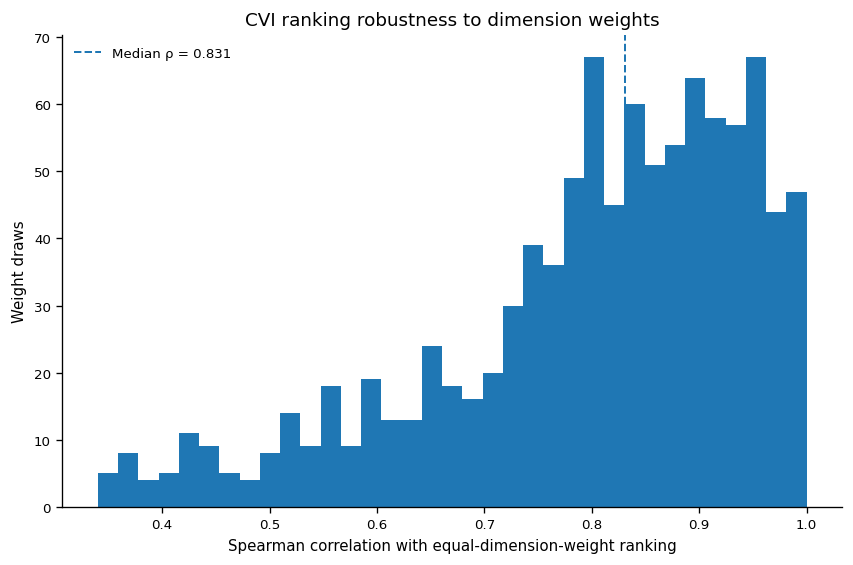

In [ ]:
# Uniform sampling over the complete E/S/AC-deficit weight simplex.
# This tests robustness of the spatial ranking to dimension weights.
rng = np.random.default_rng(CONFIG["RANDOM_SEED"])
weights_mc = rng.dirichlet(
    alpha=[1, 1, 1],
    size=CONFIG["SENSITIVITY_RUNS"],
)

base_rank = df["V_index"].rank(pct=True)
base_class = df["V_class_id"].to_numpy(dtype=float)

rows = []
for i, (w_e, w_s, w_acd) in enumerate(weights_mc):
    score = (
        w_e * df["Exposure"]
        + w_s * df["Sensitivity"]
        + w_acd * df["AdaptiveCapacityDeficit"]
    )
    pct = score.rank(pct=True)

    rho = spearmanr(base_rank, pct).statistic
    cls = pd.cut(
        pct,
        bins=[0, .2, .4, .6, .8, 1.0],
        labels=False,
        include_lowest=True,
    ).to_numpy(dtype=float)

    rows.append({
        "run": i,
        "w_exposure": w_e,
        "w_sensitivity": w_s,
        "w_adaptive_capacity_deficit": w_acd,
        "spearman_rank": rho,
        "class_agreement": float(np.mean(cls == base_class)),
    })

sens = pd.DataFrame(rows)
sens.to_csv(
    ROOT / "exports" / "dimension_weight_sensitivity.csv",
    index=False,
)

print(
    sens[[
        "spearman_rank",
        "class_agreement",
        "w_exposure",
        "w_sensitivity",
        "w_adaptive_capacity_deficit",
    ]]
    .describe()
    .round(4)
)

fig, ax = plt.subplots(figsize=(7.0, 4.6), constrained_layout=True)
ax.hist(sens["spearman_rank"], bins=35)
ax.axvline(
    sens["spearman_rank"].median(),
    linestyle="--",
    linewidth=1.2,
    label=f"Median ρ = {sens['spearman_rank'].median():.3f}",
)
ax.set_xlabel("Spearman correlation with equal-dimension-weight ranking")
ax.set_ylabel("Weight draws")
ax.set_title("CVI ranking robustness to dimension weights")
ax.legend(frameon=False)

fig.savefig(
    ROOT / "figures" / "fig20_weight_sensitivity.png",
    dpi=600, bbox_inches="tight"
)
fig.savefig(
    ROOT / "figures" / "fig20_weight_sensitivity.pdf",
    bbox_inches="tight"
)
plt.show()
plt.close(fig)

## 20. Reproducibility log, dataset manifest, and final output manifest

In [ ]:
DATASETS = {
    "boundary": boundary_source,
    "terrain": "USGS/SRTMGL1_003",
    "LST": "MODIS/061/MOD11A2",
    "NDVI": "MODIS/061/MOD13A2",
    "precipitation": "UCSB-CHG/CHIRPS/DAILY",
    "soil_moisture": "NASA/SMAP/SPL4SMGP/008",
    "land_cover": "ESA/WorldCover/v200",
    "population": f"JRC/GHSL/P2023A/GHS_POP/{CONFIG['POPULATION_YEAR']}",
    "city_access": (
        "projects/malariaatlasproject/assets/accessibility/"
        "accessibility_to_cities/2015_v1_0"
    ),
    "health_access": (
        "projects/malariaatlasproject/assets/accessibility/"
        "accessibility_to_healthcare/2019"
    ),
}

summary = {
    "run_timestamp_utc": pd.Timestamp.now(tz="UTC").isoformat(),
    "study_area": CONFIG["COUNTRY_NAMES"],
    "boundary_source": boundary_source,
    "boundary_area_km2": float(study_area_km2),
    "mountain_definition": "UNEP-WCMC/Kapos core classes 1-6 reconstructed from SRTM",
    "mountain_fraction_threshold": CONFIG["MOUNTAIN_FRACTION_MIN"],
    "period": [CONFIG["START_YEAR"], CONFIG["END_YEAR"]],
    "baseline_years": BASELINE_YEARS,
    "recent_years": RECENT_YEARS,
    "grid_crs": CONFIG["GRID_CRS"],
    "grid_resolution_m": CONFIG["GRID_RES_M"],
    "n_national_candidate_cells": int(len(grid_country)),
    "n_primary_mountain_cells": int(len(grid)),
    "n_complete_cvi_cells": int(len(df)),
    "cvi_complete_fraction": float(len(df) / len(grid)),
    "estimated_primary_domain_mountain_area_km2": float(
        grid["mountain_area_km2"].sum()
    ),
    "final_surrogate_model": final_model_name,
    "ml_features": ML_FEATURES,
    "ml_target": TARGET,
    "ml_interpretation": (
        "surrogate reproduction of constructed CVI; not independent validation"
    ),
    "shap_model": "XGBoost",
    "hotspot_permutations": CONFIG["HOTSPOT_PERMUTATIONS"],
    "hotspots_fdr": int(hot["hotspot"].sum()),
    "coldspots_fdr": int(hot["coldspot"].sum()),
    "datasets": DATASETS,
    "python_version": __import__("sys").version,
    "package_versions": {
        "earthengine_api": getattr(ee, "__version__", "unknown"),
        "numpy": np.__version__,
        "pandas": pd.__version__,
        "geopandas": gpd.__version__,
        "matplotlib": mpl.__version__,
        "xgboost": xgb_module.__version__,
        "shap": shap.__version__,
    },
}

with open(ROOT / "logs" / "reproducibility_log.json", "w") as f:
    json.dump(summary, f, indent=2, default=str)

with open(ROOT / "logs" / "dataset_manifest.json", "w") as f:
    json.dump(DATASETS, f, indent=2)

figure_rows = [
    (1, "Mountain-domain grid", "Kapos mountain fraction", "static", "11 km", "Define mountain analysis domain"),
    (2, "Summer LST anomaly", "MOD11A2", "2020–2024 vs 2016–2019", "11 km grid", "Heat-change exposure"),
    (3, "Precipitation anomaly", "CHIRPS", "2020–2024 vs 2016–2019", "11 km grid", "Hydroclimatic departure"),
    (4, "Soil-moisture anomaly", "SMAP root-zone soil moisture", "2020–2024 vs 2016–2019", "11 km grid", "Moisture exposure"),
    (5, "Vegetation-condition anomaly", "MOD13A2 NDVI", "2020–2024 vs 2016–2019", "11 km grid", "Vegetation-change sensitivity"),
    (6, "Cropland fraction", "WorldCover 2021", "2021", "11 km grid", "Land-use sensitivity"),
    (7, "Population density", "GHSL 2020", "2020", "11 km grid", "Socioeconomic sensitivity"),
    (8, "Healthcare accessibility", "MAP accessibility", "2019", "11 km grid", "Adaptive capacity"),
    ("S2", "City accessibility", "MAP accessibility", "2015", "11 km grid", "Adaptive capacity"),
    (9, "Exposure dimension", "three standardized indicators", "assessment period", "11 km", "Dimension map"),
    (10, "Sensitivity dimension", "three standardized indicators", "assessment period", "11 km", "Dimension map"),
    (11, "Adaptive-capacity deficit", "two accessibility indicators", "nominal 2015/2019", "11 km", "Dimension map"),
    (12, "Continuous CVI", "E/S/AC-deficit", "assessment period", "11 km", "Primary vulnerability surface"),
    (13, "CVI quintiles", "continuous CVI", "assessment period", "11 km", "Relative classes"),
    (14, "Mountain area by class", "mountain area + CVI class", "assessment period", "class summary", "Distribution"),
    (15, "Annual environmental context", "LST/NDVI/CHIRPS/SMAP", "2016–2024", "mountain-domain mean", "Temporal context"),
    (16, "Spatial ML parity", "CVI vs spatial OOF prediction", "spatial CV", "11 km", "Surrogate evaluation"),
    (17, "SHAP summary", "XGBoost + eight indicators", "full fitted model", "11 km", "Model interpretation"),
    (18, "Spatial OOF residuals", "selected surrogate", "spatial CV", "11 km", "Generalization diagnostic"),
    (19, "Getis–Ord Gi* hotspots", "continuous CVI", "assessment period", "11 km", "Hotspot identification"),
    (20, "Weight sensitivity", "dimension weights", f"{CONFIG['SENSITIVITY_RUNS']} draws", "11 km", "Robustness"),
]

manifest = pd.DataFrame(
    figure_rows,
    columns=[
        "figure_number",
        "title",
        "variables",
        "period",
        "spatial_scale",
        "purpose",
    ],
)
manifest.to_csv(
    ROOT / "exports" / "figure_manifest.csv",
    index=False,
)

print("\nFINAL REPRODUCIBILITY SUMMARY")
print(json.dumps(summary, indent=2))
print("\nML metrics:")
print(metrics_df.round(4))
print("\nClass exposure summary:")
print(exposure_table.round(2))
print("\nAll outputs written under:", ROOT)


FINAL REPRODUCIBILITY SUMMARY
{
  "run_timestamp_utc": "2026-10-09T05:25:26.747574+00:00",
  "study_area": [
    "Pakistan"
  ],
  "boundary_source": "FAO/GAUL/2015/level0",
  "boundary_area_km2": 788428.0367930908,
  "mountain_definition": "UNEP-WCMC/Kapos core classes 1-6 reconstructed from SRTM",
  "mountain_fraction_threshold": 0.5,
  "period": [
    2016,
    2024
  ],
  "baseline_years": [
    2016,
    2017,
    2018,
    2019
  ],
  "recent_years": [
    2020,
    2021,
    2022,
    2023,
    2024
  ],
  "grid_crs": "EPSG:6933",
  "grid_resolution_m": 11000,
  "n_national_candidate_cells": 6931,
  "n_primary_mountain_cells": 2358,
  "n_complete_cvi_cells": 1842,
  "cvi_complete_fraction": 0.7811704834605598,
  "estimated_primary_domain_mountain_area_km2": 238766.15407194436,
  "final_surrogate_model": "XGBoost",
  "ml_features": [
    "lst_anomaly_c",
    "precip_anomaly_abs_pct",
    "sm_rootzone_deficit",
    "ndvi_anomaly",
    "cropland_fraction",
    "log_population_dens

In [ ]:
!zip -r /content/climate_vulnerability_abstract_aligned_Final.zip /content/climate_vulnerability_abstract_aligned

  adding: content/climate_vulnerability_abstract_aligned/ (stored 0%)
  adding: content/climate_vulnerability_abstract_aligned/processed/ (stored 0%)
  adding: content/climate_vulnerability_abstract_aligned/processed/final_grid_results.parquet (deflated 21%)
  adding: content/climate_vulnerability_abstract_aligned/processed/vulnerability_grid.parquet (deflated 18%)
  adding: content/climate_vulnerability_abstract_aligned/processed/mountain_grid_all.parquet (deflated 22%)
  adding: content/climate_vulnerability_abstract_aligned/processed/mountain_grid_primary_complete.parquet (deflated 22%)
  adding: content/climate_vulnerability_abstract_aligned/figures/ (stored 0%)
  adding: content/climate_vulnerability_abstract_aligned/figures/fig19_gi_hotspots.png (deflated 31%)
  adding: content/climate_vulnerability_abstract_aligned/figures/fig20_weight_sensitivity.png (deflated 33%)
  adding: content/climate_vulnerability_abstract_aligned/figures/fig17_shap_summary.pdf (deflated 5%)
  adding: co

## 21. Optional Google Drive mirroring

In [ ]:
if CONFIG["SAVE_TO_DRIVE"]:
    from google.colab import drive
    import shutil

    drive.mount("/content/drive")
    drive_root = Path(
        "/content/drive/MyDrive/climate_vulnerability_abstract_aligned"
    )
    drive_root.mkdir(parents=True, exist_ok=True)

    for sub in [
        "figures", "exports", "models", "logs", "processed", "interim"
    ]:
        dest = drive_root / sub
        dest.mkdir(exist_ok=True)
        for src in (ROOT / sub).glob("*"):
            if src.is_file():
                shutil.copy2(src, dest / src.name)

    print("Outputs mirrored to", drive_root)
else:
    print(
        "SAVE_TO_DRIVE=False; outputs remain in the Colab local runtime."
    )